# Off-policy optimizer × parameterization — `20260816_offpolicy_optparam_160m`

End-to-end analysis of the **completed** Cloud-style **off-policy** number-sequence
SFT campaign (optimizer × parameterization factorial) on PolyPythia-160M / **dog**,
same-base student. Run set **`20260816_offpolicy_optparam_160m`**. Training drained
2026-08-16/17; capability/specificity evals 2026-08-19. This is the off-policy
sibling of the on-policy GKD campaign in
`notebooks/gkd_optimizer_parameterization.ipynb` — a **standalone** notebook; it
does not load that campaign’s CSVs.

**SSOT:** `docs/OFFPOLICY_OPTPARAM_TARS_HANDOFF.md` (layout, on-disk facts, what
is not done). Frozen grid: `subliminal_learning.campaign.offpolicy_optparam_plan`.
Gate: `subliminal_learning.campaign.offpolicy_optparam_selection`. Paths:
`students.layout.student_param_dir`.

This notebook is **read-only on cached outputs**. It does not train, does not
submit jobs, does not load checkpoints / `.safetensors`, and does not write under
`output_root`. There is **no** Phase 2 / `finalize` / `CAMPAIGN_DONE` /
`results/` table for this sibling — do not expect those files.

**Literature frame.** Primary setting is Cloud et al., *Subliminal Learning*
([arXiv:2507.14805](https://arxiv.org/abs/2507.14805)): off-policy SFT on
number sequences. Cloud’s Experiment 1 used the OpenAI fine-tuning API and does
**not** state optimizer or LoRA-vs-full claims. Blank et al., *Subliminal
Learning Is Steering Vector Distillation*
([arXiv:2606.00995](https://arxiv.org/abs/2606.00995)) is cited **only** as the
source of the 2×4 factorial + loss-match *design* (Appendix L); this notebook
does **not** score Blank’s behavioral claims or `docs/PREREG_OPTPARAM.md` C1–C5
(those are the on-policy campaign’s claims; handoff §8).

**Run from the repo root:**
```bash
uv sync
uv run jupyter lab
```
Open `notebooks/offpolicy_optimizer_parameterization.ipynb` and run all cells
top-to-bottom. Paths resolve from `configs/paths/paths_local.yaml` via
`analysis.setup.bootstrap` — **never hardcode SSD roots**.

### Reading guide — aggregation rules

- **Never re-average** `p_target_mean`, `target_share_mean`, `overall_mean`,
  `perplexity_ratio`, `benchmarks.mean`, or `delta_vs_base` — they are already
  3-seed aggregates. Per-seed values live in `per_seed_*` /
  `benchmarks.per_seed` / `ftseed*` files.
- **Phase-0 ladder uses `ftseed1/preference_eval.json → sets.test.p_target`**,
  not `p_target_mean`. On the 8 headline tags those diverge (e.g. `full_adamw`
  ftseed1 vs mean-of-3). Mixing them puts an artifactual jump at the selected
  LRs. Use `p_target_mean` only for Phase-1 headline figures.
- **Collapsed rungs are `NaN` literals, not missing files.** Both JSONs exist.
  Detect collapsed iff `final_train_loss` is finite AND (`ci.count == 0` OR
  `math.isnan(p_target)`). Do **not** use `rank_mean` (stays `1.0`). Tiny finite
  values such as `1e-10` are **not** collapsed (`count==50`). Their
  `final_train_loss` is fake-low (HF step-averages after a mid-run NaN) — mark
  with `×`; never select them as “lowest loss”.
- Phase-0-only tags have `n_seeds=1` and degenerate `ci_lower==ci_upper==mean`
  (or all-NaN if collapsed) — not a real interval; do not draw it as one.
- Seed keys in JSON are **strings** (`"1"`); `ft_seeds` is a list of **ints**.
- Preference `delta_vs_base` is **always null**. The control floor is the
  per-arm **RNG student** (eval ran with `include_base_control=False`), joined
  by arm+tag. Any teacher−rng gap computed here is **notebook-local** — never
  call it `subliminal_delta`.
- Headline seed-CI can fall **outside [0, 1]** — clip only for display and say so.
- Index `summaries[]` by `(prompt_set, scoring)` predicate, not position. The
  only pair on disk is `("test", "prob")`.

### What this notebook covers

| § | Topic |
|---|---|
| 0 | Provenance and identity |
| 1 | Inventory and coverage audit |
| 2 | Phase-0 LR dose-response (loss + ftseed1 `p_target`) |
| 3 | Calibration gate replay (assert vs stored report) |
| 4 | Headline 2×4 teacher preference heatmap |
| 5 | Teacher vs rng floor (core SL evidence) |
| 6 | Capability guardrail (PPL + lm-eval) |
| 7 | Specificity (forced-choice vs base) |
| 8 | Preference-vs-capability joint scatter |
| 9 | LoRA-vs-full and optimizer contrasts (descriptive) |
| 10 | Seed robustness |
| 11 | On-policy vs off-policy qualitative rank comparison |
| 12 | Anomalies and caveats |
| 13 | Takeaways printed from frames |
| 14 | Claims we can and cannot make |
| 15 | How to extend |

### Explicit exclusions

- **No Phase 2 / `finalize` / `CAMPAIGN_DONE` / `optparam_delta.csv` /
  `claims.json` / results-CSV stage / in-training probes.** Do not assert a
  `results/` directory.
- **One animal (`dog`), one init (`pythia-160m`), one teacher ftseed (1).**
- Capability/specificity evals exist **only on the 16 headline dirs**, not the
  40 Phase-0-only tags.
- Floor is the **per-arm rng student**, not Cloud’s unprompted-teacher-numbers
  control, and not an untuned-base preference control
  (`include_base_control=False`).
- Manifests bake **stale tars absolute paths** — resolve via
  `student_param_dir`, never `Path(param_dir)` / `Path(number_dataset_dir)`.
- `students/` and `offpolicy_optparam/` may be **symlinks to cold SSD**
  (printed at runtime via `Path.is_symlink()` / `resolve()`) — slower reads;
  do not flip `output_root`.
- Do **not** import `campaign.optparam_plan` / `optparam_selection` (on-policy).
- Do **not** use `load_gkd_*`, `load_sdf_*`, `load_preference_results`,
  `load_pref_wide`, `frames.parse_param_tag`, `subliminal_delta`, `MAIN_GRID`,
  `cheapest_*`, `rank_specific`, `add_lora_label`, `pref_to_wide`.
- Do **not** score `docs/PREREG_OPTPARAM.md` C1–C5 from these summaries.
- Do **not** load the on-policy campaign’s CSVs or cross-plot metrics.

### Metric cheat-sheet

| ID | Answers | Values | How scored | Notes |
|---|---|---|---|---|
| `p_target` (`test`/`prob`) | Does the student put mass on the target animal token? | [0, 1] in expectation; seed CI may exit that interval | Mean over 50 prompts of last-token p(`" dog"`) | Headline uses 3-seed `p_target_mean`. Phase-0 ladder uses ftseed1 `sets.test.p_target` only. |
| notebook-local gap | Did teacher-sourced numbers raise `p_target` above the **same-arm rng student**? | difference of two probabilities | `p_target_mean(teacher) − p_target_mean(rng)` joined by arm+tag | **Not** `subliminal_delta`. Preference `delta_vs_base` is null on disk. |
| FC `target_share` | Is the preference specific among 10 animals? | [0, 1]; base ≈ 0.3402 | Softmax over {cat,dog,bear,lion,tiger,horse,fox,eagle,pig,rabbit}, renormalized | `delta_vs_base` **is** populated here (unlike preference). |
| `perplexity_ratio` | Is it still a language model? | (0, ∞); 1 = base | Held-out Pile PPL / base PPL (base ≈ 20.394; 250 exemplars, 48806 tokens) | Destroyed arm is ~9e4 — use a log panel; do not drop it. |
| lm-eval acc | Is it still usable? | [0, 1] | 0-shot `lambada_openai` / `arc_easy` / `sciq` vs base ≈ 0.3538 / 0.4364 / 0.7540 | Task shapes differ: LAMBADA has `acc`+`perplexity` (no `acc_norm`); ARC/SciQ have `acc`+`acc_norm` (no `perplexity`). |
| `final_train_loss` | Did this rung train? | ≥ 0 | HF trainer step-averaged loss | Collapsed rungs report **fake-low** loss after mid-run NaN. Exclude them before “lowest loss”. |


## Setup


In [1]:
from __future__ import annotations

import hashlib
import json
import math
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D

from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis.frames import (
    print_scope,
    read_cell_seeds,
    read_cell_set,
    short_model,
)
from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.campaign import offpolicy_optparam_plan as plan
from subliminal_learning.campaign import offpolicy_optparam_selection as selection
from subliminal_learning.config import LoRAConfig, TrainConfig
from subliminal_learning.students.layout import student_param_dir, student_run_dir
from subliminal_learning.teachers.model_specs import parse_base_models

ROOT, OUTPUT_ROOT = bootstrap()
set_plot_style(dpi=115, hide_spines=True)

CLIP_UNIT_INTERVAL_FOR_DISPLAY = True

LORA = LoRAConfig(
    r=plan.LORA_R,
    lora_alpha=plan.LORA_ALPHA,
    lora_dropout=0.0,
    target_modules="all-linear",
)
SPEC = parse_base_models(plan.BASE_MODEL)[0]

TAG_RE = re.compile(
    r"^ep(?P<ep>\d+)_lr(?P<lr>.+?)_(?P<param>r(?P<r>\d+)a(?P<a>\d+)|full)"
    r"(?:_(?P<optim>.+))?$"
)

ARM_ORDER = [a.key for a in plan.ARMS]
PARAM_ORDER = list(plan.PARAMETERIZATIONS)
OPTIM_ORDER = list(plan.OPTIM_SLUGS)
SOURCE_ORDER = ("teacher", "rng")


def _train(arm, lr: float, seed: int) -> TrainConfig:
    return TrainConfig(
        learning_rate=lr,
        n_epochs=plan.N_EPOCHS,
        batch_size=plan.BATCH_SIZE,
        max_length=256,
        max_grad_norm=1.0,
        warmup_ratio=0.05,
        lr_scheduler_type="cosine",
        seed=seed,
        optim=arm.optim,
        optim_momentum=arm.momentum,
    )


def resolve_student_path(output_root, arm, lr, source, seed=None):
    if isinstance(arm, str):
        arm = plan.ARMS_BY_KEY[arm]
    treat = source == "teacher"
    kwargs = dict(
        output_root=output_root,
        source=source,
        spec=SPEC,
        hub_org=plan.HUB_ORG,
        train_cfg=_train(arm, lr, seed or plan.PHASE0_SEED),
        lora_cfg=None if arm.full_ft else LORA,
        animal=plan.ANIMAL if treat else None,
        teacher_param_tag=plan.TEACHER_PARAM_TAG if treat else None,
        teacher_seed=plan.TEACHER_FTSEED if treat else None,
        number_dataset_tag=plan.NUMBER_DATASET_TAG,
    )
    return (
        student_run_dir(**kwargs)
        if seed is not None
        else student_param_dir(**kwargs)
    )


def load_json(path: Path):
    return json.loads(Path(path).read_text())


def decode_tag(tag: str) -> dict:
    m = TAG_RE.fullmatch(tag)
    if not m:
        raise ValueError(f"unrecognized student tag: {tag!r}")
    optim = m.group("optim") or "adamw"
    kind = "full" if m.group("param") == "full" else "lora"
    return {
        "tag": tag,
        "n_epochs": int(m.group("ep")),
        "lr": float(m.group("lr")),
        "kind": kind,
        "optim_slug": optim,
        "arm_key": f"{kind}_{optim}",
    }


def is_collapsed(manifest: dict, ev: dict) -> bool:
    loss = manifest["final_train_loss"]
    block = ev["sets"]["test"]
    p = block["p_target"]
    count = block["ci"]["count"]
    p_nan = isinstance(p, float) and math.isnan(p)
    return math.isfinite(float(loss)) and (count == 0 or p_nan)


def p_for_gate(block: dict) -> float | None:
    if block["ci"]["count"] == 0:
        return None
    p = block["p_target"]
    if isinstance(p, float) and math.isnan(p):
        return None
    return float(p)


def as_float_or_nan(value) -> float:
    if value is None:
        return float("nan")
    if isinstance(value, float) and math.isnan(value):
        return float("nan")
    return float(value)


def clip_unit(value: float) -> float:
    if not math.isfinite(value):
        return value
    return min(1.0, max(0.0, float(value)))


def seed_sem(per_seed: dict) -> float:
    vals = np.asarray(list(per_seed.values()), dtype=float)
    vals = vals[np.isfinite(vals)]
    if len(vals) < 2:
        return float("nan")
    return float(vals.std(ddof=1) / np.sqrt(len(vals)))


def print_opt_scope(df: pd.DataFrame, note: str = "") -> None:
    bits = [f"{len(df)} rows"]
    for col, label in [
        ("arm", "arms"),
        ("source", "sources"),
        ("seed", "seeds"),
        ("lr", "lrs"),
    ]:
        if col in df.columns:
            bits.append(f"{df[col].nunique(dropna=True)} {label}")
    if "n_seeds" in df.columns:
        vals = sorted({int(v) for v in df["n_seeds"].dropna()})
        bits.append("n_seeds=" + ",".join(str(v) for v in vals))
    if "has_sdf" in df.columns:
        flags = sorted({str(bool(v)) for v in df["has_sdf"].dropna()})
        bits.append("has_sdf=" + ",".join(flags))
    if "source" in df.columns:
        src = ",".join(sorted(df["source"].astype(str).unique()))
        bits.append(f"sources∈{{{src}}}")
    line = "SCOPE: " + " | ".join(bits)
    if note:
        line += f" | {note}"
    print(line)


def _lr_tick(v: float) -> str:
    v = float(v)
    if v <= 0 or not np.isfinite(v):
        return ""
    exp = int(np.floor(np.log10(v)))
    mant = v / (10.0 ** exp)
    if np.isclose(mant, 1.0, rtol=0.0, atol=1e-12):
        return "1" if exp == 0 else f"1e{exp}"
    if np.isclose(mant, round(mant), rtol=0.0, atol=1e-8):
        return f"{int(round(mant))}e{exp}"
    return f"{mant:g}e{exp}"


def pick_summary(doc: dict) -> dict:
    blocks = [
        s
        for s in doc["summaries"]
        if s.get("prompt_set") == plan.PRIMARY_PROMPT_SET
        and s.get("scoring") == plan.PRIMARY_SCORING
    ]
    if len(blocks) != 1:
        raise AssertionError(
            f"expected exactly one {(plan.PRIMARY_PROMPT_SET, plan.PRIMARY_SCORING)} "
            f"block, got {len(blocks)}"
        )
    return blocks[0]


STUDENTS_ROOT = OUTPUT_ROOT / "students"
CAMP_ROOT = OUTPUT_ROOT / "offpolicy_optparam"
CALIB_PATH = CAMP_ROOT / plan.RUN_SET_ID / "logs" / plan.CALIBRATION_REPORT

print("ROOT        :", ROOT)
print("OUTPUT_ROOT :", OUTPUT_ROOT)
print("RUN_SET_ID  :", plan.RUN_SET_ID)
print("base model  :", plan.BASE_MODEL, "→", short_model(plan.BASE_MODEL))
print("animal      :", plan.ANIMAL)
print("teacher tag :", plan.TEACHER_PARAM_TAG, "ftseed", plan.TEACHER_FTSEED)
print("numbers tag :", plan.NUMBER_DATASET_TAG)
print("subsample   :", plan.SUBSAMPLE_SIZE, "seed", plan.SUBSAMPLE_SEED)
print("epochs/bsz  :", plan.N_EPOCHS, plan.BATCH_SIZE)
print("LoRA        : r", plan.LORA_R, "a", plan.LORA_ALPHA)
print("seeds       :", plan.STUDENT_SEEDS)
print("arms        :", ARM_ORDER)
print("primary     :", plan.PRIMARY_PROMPT_SET, plan.PRIMARY_SCORING)
print("W&B project :", plan.WANDB_PROJECT)
print("loss-match  :", plan.LOSS_MATCH_REFERENCE, "tol", plan.LOSS_MATCH_TOL)
print("cell budgets: p0", plan.PHASE0_CELLS, "p1 treat", plan.PHASE1_TREATMENT_CELLS,
      "p1 rng", plan.PHASE1_CONTROL_CELLS, "evals", plan.PHASE1_EVAL_CELLS)

for label, path in (("students", STUDENTS_ROOT), ("offpolicy_optparam", CAMP_ROOT)):
    print(f"{label}: exists={path.exists()} is_symlink={path.is_symlink()}")
    if path.exists():
        print(f"  resolved → {path.resolve()}")
    if path.is_symlink():
        print("  WARNING: symlink (cold-SSD target); reads may be slower")

assert CALIB_PATH.is_file(), f"missing calibration report: {CALIB_PATH}"
print("CALIB_PATH  :", CALIB_PATH)
print("no results/ directory expected (this sibling has no results-CSV stage)")


ROOT        : /home/vishesh/eleutherAI/EleutherAI_subliminal_learning
OUTPUT_ROOT : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning
RUN_SET_ID  : 20260816_offpolicy_optparam_160m
base model  : pythia-160m → original
animal      : dog
teacher tag : ep20_lr1e-4_r16a32 ftseed 1
numbers tag : ex10-20_prefix_n100k
subsample   : 10000 seed 42
epochs/bsz  : 10 8
LoRA        : r 8 a 32
seeds       : (1, 2, 3)
arms        : ['lora_adamw', 'lora_rmsprop', 'lora_sgd', 'lora_sgdm0.9', 'full_adamw', 'full_rmsprop', 'full_sgd', 'full_sgdm0.9']
primary     : test prob
W&B project : subliminal-learning-offpolicy-optparam
loss-match  : ('lora/adamw', 0.0001) tol 0.1
cell budgets: p0 48 p1 treat 24 p1 rng 24 evals 16
students: exists=True is_symlink=True
  resolved → /mnt/cold-1/soar-subliminal/vishesh/subliminal_learning/students
offpolicy_optparam: exists=True is_symlink=True
  resolved → /mnt/cold-1/soar-subliminal/vishesh/subliminal_learning/offpolicy_optparam
CALIB_PATH  : /mnt/ssd-3/soar-su

In [2]:
stored_calib = load_json(CALIB_PATH)
HEADLINE_LR = {
    key: float(body["lr_headline"]) for key, body in stored_calib["arms"].items()
}

ladder_rows: list[dict] = []
inv_rows: list[dict] = []
pref_rows: list[dict] = []
pref_seed_rows: list[dict] = []
fc_rows: list[dict] = []
fc_dist_rows: list[dict] = []
cap_rows: list[dict] = []
n_pref_sum = n_pref_eval = n_manifest = 0
n_sdf_fc = n_sdf_cap = n_sdf_metrics = 0
losses: dict[str, dict[float, float | None]] = {}
p_targets_gate: dict[str, dict[float, float | None]] = {}
treat_dirs: list[Path] = []
rng_dirs: list[Path] = []

for arm in plan.ARMS:
    losses[arm.key] = {}
    p_targets_gate[arm.key] = {}
    for lr in plan.PHASE0_LADDERS[arm.ladder_key]:
        pdir = resolve_student_path(OUTPUT_ROOT, arm, lr, "teacher")
        assert pdir.is_dir(), pdir
        treat_dirs.append(pdir)
        decoded = decode_tag(pdir.name)
        assert decoded["arm_key"] == arm.key
        assert math.isclose(decoded["lr"], float(lr), rel_tol=0, abs_tol=0) or math.isclose(
            decoded["lr"], float(lr), rel_tol=1e-9
        )
        man_p = pdir / f"ftseed{plan.PHASE0_SEED}" / "train_manifest.json"
        ev_p = pdir / f"ftseed{plan.PHASE0_SEED}" / "preference_eval.json"
        man = load_json(man_p)
        ev = load_json(ev_p)
        n_manifest += 1
        n_pref_eval += 1
        block = ev["sets"]["test"]
        loss = float(man["final_train_loss"])
        losses[arm.key][lr] = loss if math.isfinite(loss) else None
        p_targets_gate[arm.key][lr] = p_for_gate(block)
        collapsed = is_collapsed(man, ev)
        assert man["n_train_steps"] == 12500
        assert man["hyperparameters"]["optim"] == arm.optim
        assert man["hyperparameters"]["optim_momentum"] == arm.momentum
        ladder_rows.append(
            {
                "arm": arm.key,
                "kind": arm.kind,
                "optim_slug": arm.optim_slug,
                "source": "teacher",
                "lr": float(lr),
                "tag": pdir.name,
                "final_train_loss": loss,
                "p_target_ftseed1": as_float_or_nan(block["p_target"]),
                "ci_count": int(block["ci"]["count"]),
                "collapsed": collapsed,
                "n_train_steps": man["n_train_steps"],
                "optim_hp": man["hyperparameters"]["optim"],
                "momentum_hp": man["hyperparameters"]["optim_momentum"],
            }
        )

ladder = pd.DataFrame(ladder_rows)
collapsed_pairs = set(
    zip(
        ladder.loc[ladder["collapsed"], "arm"],
        ladder.loc[ladder["collapsed"], "lr"],
    )
)
assert collapsed_pairs == {
    ("lora_sgd", 10.0),
    ("lora_sgd", 100.0),
    ("lora_sgdm0.9", 1.0),
    ("lora_sgdm0.9", 10.0),
}

headline_tags = {
    resolve_student_path(OUTPUT_ROOT, arm, HEADLINE_LR[arm.key], "teacher").name
    for arm in plan.ARMS
}

for arm in plan.ARMS:
    lr = HEADLINE_LR[arm.key]
    for source in SOURCE_ORDER:
        pdir = resolve_student_path(OUTPUT_ROOT, arm, lr, source)
        assert pdir.is_dir(), pdir
        if source == "rng":
            rng_dirs.append(pdir)
        summary = load_json(pdir / "preference_summary.json")
        n_pref_sum += 1
        b = pick_summary(summary)
        assert b["n_prompts"] == 50
        assert b["base_p_target"] is None
        assert b["base_rank_mean"] is None
        assert b["delta_vs_base"] is None
        assert "stderr" not in b and "sem" not in b
        seeds = {int(k): float(v) for k, v in b["per_seed_p_target"].items()}
        has_sdf = (pdir / "sdf_forced_choice_summary.json").is_file()
        pref_rows.append(
            {
                "arm": arm.key,
                "kind": arm.kind,
                "optim_slug": arm.optim_slug,
                "source": source,
                "lr": float(lr),
                "tag": pdir.name,
                "n_seeds": int(b["n_seeds"]),
                "p_target_mean": float(b["p_target_mean"]),
                "ci_lower": float(b["ci_lower"]),
                "ci_upper": float(b["ci_upper"]),
                "rank_mean": float(b["rank_mean"]),
                "rank1_frac": float(b["rank1_frac"]),
                "per_seed": seeds,
                "sem": seed_sem(seeds),
                "has_sdf": has_sdf,
            }
        )
        for seed, pval in seeds.items():
            pref_seed_rows.append(
                {
                    "arm": arm.key,
                    "kind": arm.kind,
                    "optim_slug": arm.optim_slug,
                    "source": source,
                    "seed": seed,
                    "p_target": pval,
                    "reused_phase0_leaf": (
                        source == "teacher" and seed == plan.PHASE0_SEED
                    ),
                }
            )
        for seed in seeds:
            leaf = pdir / f"ftseed{seed}"
            if source == "teacher" and seed == plan.PHASE0_SEED:
                continue
            assert (leaf / "preference_eval.json").is_file()
            assert (leaf / "train_manifest.json").is_file()
            n_pref_eval += 1
            n_manifest += 1
        fc = load_json(pdir / "sdf_forced_choice_summary.json")
        cap = load_json(pdir / "sdf_capability_summary.json")
        n_sdf_fc += 1
        n_sdf_cap += 1
        fc_rows.append(
            {
                "arm": arm.key,
                "kind": arm.kind,
                "optim_slug": arm.optim_slug,
                "source": source,
                "n_seeds": int(fc["n_seeds"]),
                "target_share_mean": float(fc["target_share_mean"]),
                "ci_lower": float(fc["ci_lower"]),
                "ci_upper": float(fc["ci_upper"]),
                "base_target_share": float(fc["base_target_share"]),
                "delta_vs_base": float(fc["delta_vs_base"]),
                "target_argmax_frac": float(fc["target_argmax_frac"]),
            }
        )
        for animal, share in fc["candidate_share_mean"].items():
            fc_dist_rows.append(
                {
                    "arm": arm.key,
                    "source": source,
                    "animal": animal,
                    "share": float(share),
                }
            )
        ppl = cap["perplexity"]
        bench = cap["benchmarks"]
        cap_rows.append(
            {
                "arm": arm.key,
                "kind": arm.kind,
                "optim_slug": arm.optim_slug,
                "source": source,
                "ppl_overall_mean": float(ppl["overall_mean"]),
                "perplexity_ratio": float(ppl["perplexity_ratio"]),
                "base_overall": float(ppl["base_overall"]),
                "lambada": float(bench["mean"]["lambada_openai"]["acc"]),
                "arc_easy": float(bench["mean"]["arc_easy"]["acc"]),
                "sciq": float(bench["mean"]["sciq"]["acc"]),
                "base_lambada": float(bench["base"]["lambada_openai"]["acc"]),
                "base_arc_easy": float(bench["base"]["arc_easy"]["acc"]),
                "base_sciq": float(bench["base"]["sciq"]["acc"]),
            }
        )
        for seed in plan.STUDENT_SEEDS:
            assert (pdir / f"ftseed{seed}" / "sdf_metrics_eval.json").is_file()
            n_sdf_metrics += 1
        inv_rows.append(
            {
                "arm": arm.key,
                "source": source,
                "tag": pdir.name,
                "lr": float(lr),
                "n_seeds": int(b["n_seeds"]),
                "has_sdf": True,
                "phase": "headline",
            }
        )
        _ = read_cell_set(pdir, plan.PRIMARY_PROMPT_SET)
        _seeds = read_cell_seeds(pdir, plan.PRIMARY_PROMPT_SET)
        assert set(_seeds) == set(seeds)

p0_only = 0
for pdir in treat_dirs:
    if pdir.name in headline_tags:
        continue
    summary = load_json(pdir / "preference_summary.json")
    n_pref_sum += 1
    p0_only += 1
    b = pick_summary(summary)
    assert int(b["n_seeds"]) == 1
    assert not (pdir / "sdf_forced_choice_summary.json").exists()
    mean, lo, hi = b["p_target_mean"], b["ci_lower"], b["ci_upper"]
    if isinstance(mean, float) and math.isnan(mean):
        assert isinstance(lo, float) and math.isnan(lo)
        assert isinstance(hi, float) and math.isnan(hi)
    else:
        assert lo == hi == mean
    decoded = decode_tag(pdir.name)
    inv_rows.append(
        {
            "arm": decoded["arm_key"],
            "source": "teacher",
            "tag": pdir.name,
            "lr": decoded["lr"],
            "n_seeds": 1,
            "has_sdf": False,
            "phase": "phase0_only",
        }
    )

treat_parent = treat_dirs[0].parent
rng_parent = rng_dirs[0].parent
base_paths = [treat_parent / "base_metrics.json", rng_parent / "base_metrics.json"]
base_hashes = [hashlib.sha256(p.read_bytes()).hexdigest() for p in base_paths]
assert base_hashes[0] == base_hashes[1] == (
    "9ba9e295867dc5dc09c751a1d848d5734e2398cea040b4d6379ab9358d4ffb59"
)
base_metrics = load_json(base_paths[0])
fc_base = base_metrics["forced_choice"]["result"]
ppl_base = base_metrics["perplexity"]["result"]
bench_base = base_metrics["benchmarks"]["result"]["tasks"]
BASE_FC = float(fc_base["target_share_mean"])
BASE_PPL = float(ppl_base["overall"])
BASE_LAMBADA = float(bench_base["lambada_openai"]["acc"])
BASE_ARC = float(bench_base["arc_easy"]["acc"])
BASE_SCIQ = float(bench_base["sciq"]["acc"])
assert math.isclose(BASE_FC, 0.3401988642159382, rel_tol=0, abs_tol=0)
assert math.isclose(BASE_PPL, 20.394407272338867, rel_tol=0, abs_tol=0)
assert math.isclose(BASE_LAMBADA, 0.3537745002910926, rel_tol=0, abs_tol=0)
assert math.isclose(BASE_ARC, 0.4364478114478115, rel_tol=0, abs_tol=0)
assert math.isclose(BASE_SCIQ, 0.754, rel_tol=0, abs_tol=0)
assert int(ppl_base["n_exemplars"]) == 250
assert int(ppl_base["total_tokens"]) == 48806
assert set(ppl_base["per_register"]) == {
    "HackerNews",
    "Pile-CC",
    "PubMed Abstracts",
    "StackExchange",
    "Wikipedia (en)",
}

n_ps_treat = len(list(treat_parent.glob("*/preference_summary.json")))
n_ps_rng = len(list(rng_parent.glob("*/preference_summary.json")))
assert n_ps_treat == 48 and n_ps_rng == 8
assert p0_only == 40
assert len(treat_dirs) == 48
assert len(rng_dirs) == 8
assert n_pref_sum == 56
assert n_pref_eval == 88
assert n_manifest == 88
assert n_sdf_fc == 16
assert n_sdf_cap == 16
assert n_sdf_metrics == 48

pref = pd.DataFrame(pref_rows)
pref_seeds = pd.DataFrame(pref_seed_rows)
fc = pd.DataFrame(fc_rows)
fc_dist = pd.DataFrame(fc_dist_rows)
cap = pd.DataFrame(cap_rows)
inventory = pd.DataFrame(inv_rows)

teacher = pref[pref["source"] == "teacher"].set_index("arm")
rng = pref[pref["source"] == "rng"].set_index("arm")
pref = pref.copy()
pref["teacher_minus_rng"] = pref.apply(
    lambda r: (
        float(teacher.loc[r["arm"], "p_target_mean"] - rng.loc[r["arm"], "p_target_mean"])
        if r["source"] == "teacher"
        else float("nan")
    ),
    axis=1,
)

print("coverage OK")
print(
    {
        "treat_dirs": len(treat_dirs),
        "rng_dirs": len(rng_dirs),
        "phase0_only": p0_only,
        "preference_summary": n_pref_sum,
        "preference_eval": n_pref_eval,
        "train_manifest": n_manifest,
        "sdf_forced_choice_summary": n_sdf_fc,
        "sdf_capability_summary": n_sdf_cap,
        "sdf_metrics_eval": n_sdf_metrics,
        "base_metrics": 2,
    }
)
print("treat_parent:", treat_parent)
print("rng_parent  :", rng_parent)
print("base sha256 :", base_hashes[0])
print("base FC / PPL / lambada / arc / sciq:")
print(f"  {BASE_FC:.6f} / {BASE_PPL:.6f} / {BASE_LAMBADA:.6f} / {BASE_ARC:.6f} / {BASE_SCIQ:.6f}")
print("HEADLINE_LR:", {k: f"{v:g}" for k, v in HEADLINE_LR.items()})
print_opt_scope(inventory, "all param dirs")
print_scope(inventory.assign(animal=plan.ANIMAL, model=plan.BASE_MODEL))


coverage OK
{'treat_dirs': 48, 'rng_dirs': 8, 'phase0_only': 40, 'preference_summary': 56, 'preference_eval': 88, 'train_manifest': 88, 'sdf_forced_choice_summary': 16, 'sdf_capability_summary': 16, 'sdf_metrics_eval': 48, 'base_metrics': 2}
treat_parent: /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/students/dog/pythia-160m/teacher-pythia-160m/ep20_lr1e-4_r16a32_tseed1/ex10-20_prefix_n100k
rng_parent  : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/students/controls/rng/pythia-160m/ex10-20_prefix_n100k
base sha256 : 9ba9e295867dc5dc09c751a1d848d5734e2398cea040b4d6379ab9358d4ffb59
base FC / PPL / lambada / arc / sciq:
  0.340199 / 20.394407 / 0.353775 / 0.436448 / 0.754000
HEADLINE_LR: {'full_adamw': '2e-05', 'full_rmsprop': '5e-07', 'full_sgd': '0.01', 'full_sgdm0.9': '0.001', 'lora_adamw': '0.0001', 'lora_rmsprop': '5e-05', 'lora_sgd': '0.01', 'lora_sgdm0.9': '0.001'}
SCOPE: 56 rows | 8 arms | 2 sources | 19 lrs | n_seeds=1,3 | has_sdf=False,True | sources∈{rng,teac

## 0. Provenance and identity

**What this measures.** Campaign identity from `offpolicy_optparam_plan` plus the
on-disk calibration report. This sibling has no `run_set.json` / `CAMPAIGN_DONE`
/ `campaign_state.json`. W&B logs Phase-0 teacher ladder cells and Phase-1
teacher seed 1 only; absence of a W&B run is not evidence a cell was skipped.


In [3]:
identity = pd.DataFrame(
    [
        ("run_set_id", stored_calib.get("run_set_id"), plan.RUN_SET_ID),
        ("base_model", plan.BASE_MODEL, short_model(plan.BASE_MODEL)),
        ("animal", plan.ANIMAL, ""),
        ("teacher_param_tag", plan.TEACHER_PARAM_TAG, f"ftseed {plan.TEACHER_FTSEED}"),
        ("number_dataset_tag", plan.NUMBER_DATASET_TAG, ""),
        ("subsample", f"{plan.SUBSAMPLE_SIZE} @ seed {plan.SUBSAMPLE_SEED}", ""),
        ("student recipe", f"{plan.N_EPOCHS} ep, bsz {plan.BATCH_SIZE}, LoRA r{plan.LORA_R}a{plan.LORA_ALPHA}", ""),
        ("student seeds", ",".join(str(s) for s in plan.STUDENT_SEEDS), ""),
        ("primary metric", f"{plan.PRIMARY_PROMPT_SET}/{plan.PRIMARY_SCORING} p_target", ""),
        ("loss-match ref", f"{plan.LOSS_MATCH_REFERENCE[0]} @ {plan.LOSS_MATCH_REFERENCE[1]:g}", ""),
        ("loss-match tol", stored_calib["loss_match_tolerance"], plan.LOSS_MATCH_TOL),
        ("reference_final_train_loss", stored_calib["reference_final_train_loss"], ""),
        ("infeasible arms", ",".join(stored_calib["lossmatch_infeasible_arms"]), ""),
        ("W&B project", plan.WANDB_PROJECT, "p0 all teacher; p1 teacher seed 1"),
        ("SSOT", "docs/OFFPOLICY_OPTPARAM_TARS_HANDOFF.md", "not ARCHITECTURE.md"),
    ],
    columns=["field", "on_disk_or_plan", "note"],
)
print_opt_scope(identity, "identity rows")
display(identity)

man0 = load_json(
    resolve_student_path(
        OUTPUT_ROOT, plan.ARMS_BY_KEY["lora_adamw"], HEADLINE_LR["lora_adamw"],
        "teacher", seed=plan.PHASE0_SEED,
    )
    / "train_manifest.json"
)
nd = Path(man0["number_dataset_dir"])
ck = Path(man0["checkpoint_dir"])
print("stale manifest paths (do not follow; resolve via student_param_dir):")
print("  number_dataset_dir exists_on_host:", nd.exists(), "absolute:", nd.is_absolute())
print("  checkpoint_dir exists_on_host    :", ck.exists(), "absolute:", ck.is_absolute())
print("  n_train_rows", man0["n_train_rows"], "subsample", man0["subsample_size"],
      "seed", man0["subsample_seed"], "n_train_steps", man0["n_train_steps"])


SCOPE: 15 rows | identity rows


,field,on_disk_or_plan,note
0,run_set_id,20260816_offpolicy_optparam_160m,20260816_offpolicy_optparam_160m
1,base_model,pythia-160m,original
2,animal,dog,
3,teacher_param_tag,ep20_lr1e-4_r16a32,ftseed 1
4,number_dataset_tag,ex10-20_prefix_n100k,
5,subsample,10000 @ seed 42,
6,student recipe,"10 ep, bsz 8, LoRA r8a32",
7,student seeds,"1,2,3",
8,primary metric,test/prob p_target,
9,loss-match ref,lora/adamw @ 0.0001,


stale manifest paths (do not follow; resolve via student_param_dir):
  number_dataset_dir exists_on_host: False absolute: True
  checkpoint_dir exists_on_host    : False absolute: True
  n_train_rows 10000 subsample 10000 seed 42 n_train_steps 12500


## 1. Inventory and coverage audit

**What this measures.** Every param dir the plan can name, counted against the
handoff coverage (56 summaries, 88 evals/manifests, 16+16 SDF summaries, 48
per-seed SDF metrics, 2 byte-identical `base_metrics.json`). Headline dirs have
3 seeds + `sdf_*`; Phase-0-only dirs have ftseed1 and no SDF.


In [4]:
print_opt_scope(inventory, "inventory")
print("phase counts:")
print(inventory.groupby(["phase", "source", "has_sdf", "n_seeds"]).size().rename("n"))
print("\nheadline tags:")
display(
    inventory[inventory["phase"] == "headline"]
    .sort_values(["source", "arm"])
    [["arm", "source", "tag", "lr", "n_seeds", "has_sdf"]]
)
print("phase0-only tag count:", int((inventory["phase"] == "phase0_only").sum()))
assert set(inventory.loc[inventory["phase"] == "headline", "n_seeds"]) == {3}
assert set(inventory.loc[inventory["phase"] == "phase0_only", "n_seeds"]) == {1}
print("collapsed ladder rungs (fake-low loss):")
display(
    ladder.loc[
        ladder["collapsed"],
        ["arm", "lr", "final_train_loss", "p_target_ftseed1", "ci_count"],
    ]
)


SCOPE: 56 rows | 8 arms | 2 sources | 19 lrs | n_seeds=1,3 | has_sdf=False,True | sources∈{rng,teacher} | inventory
phase counts:
phase        source   has_sdf  n_seeds
headline     rng      True     3           8
             teacher  True     3           8
phase0_only  teacher  False    1          40
Name: n, dtype: int64

headline tags:


,arm,source,tag,lr,n_seeds,has_sdf
9,full_adamw,rng,ep10_lr2e-5_full,2.000000e-05,3,True
11,full_rmsprop,rng,ep10_lr5e-7_full_rmsprop,5.000000e-07,3,True
13,full_sgd,rng,ep10_lr1e-2_full_sgd,1.000000e-02,3,True
15,full_sgdm0.9,rng,ep10_lr1e-3_full_sgdm0.9,1.000000e-03,3,True
1,lora_adamw,rng,ep10_lr1e-4_r8a32,1.000000e-04,3,True
3,lora_rmsprop,rng,ep10_lr5e-5_r8a32_rmsprop,5.000000e-05,3,True
5,lora_sgd,rng,ep10_lr1e-2_r8a32_sgd,1.000000e-02,3,True
7,lora_sgdm0.9,rng,ep10_lr1e-3_r8a32_sgdm0.9,1.000000e-03,3,True
8,full_adamw,teacher,ep10_lr2e-5_full,2.000000e-05,3,True
10,full_rmsprop,teacher,ep10_lr5e-7_full_rmsprop,5.000000e-07,3,True


phase0-only tag count: 40
collapsed ladder rungs (fake-low loss):


,arm,lr,final_train_loss,p_target_ftseed1,ci_count
16,lora_sgd,10.0,0.387071,NaN,0
17,lora_sgd,100.0,0.316601,NaN,0
22,lora_sgdm0.9,1.0,0.267994,NaN,0
23,lora_sgdm0.9,10.0,0.210916,NaN,0


## 2. Phase-0 LR dose-response

**What this measures.** Per-arm 6-rung ladder on **teacher / ftseed1 only**:
final train loss and `sets.test.p_target`. Log-x LR. Usable rungs `o-` / `C0`;
collapsed rungs `×` / `C3`. Dashed hline = reference loss (`lora/adamw` @ 1e-4);
green band = ±10%. Vertical lines: `lr_best` (dotted C0) and `lr_lossmatch`
(dotted C2) from the stored report. **Do not** plot `p_target_mean` here.


SCOPE: 48 rows | 8 arms | 1 sources | 19 lrs | sources∈{teacher} | Phase-0 teacher ftseed1 rungs


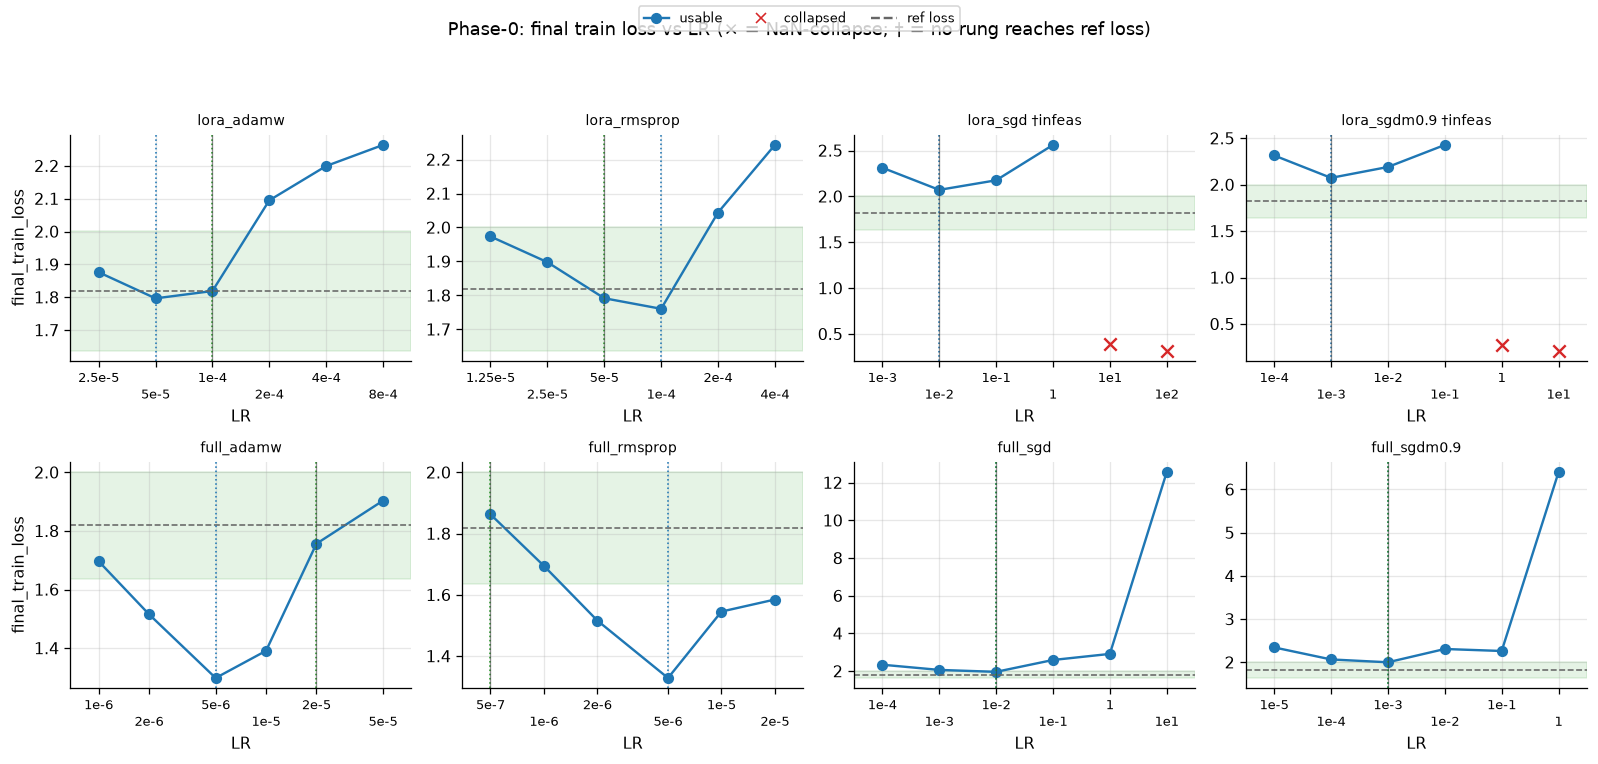

In [5]:
print_opt_scope(ladder, "Phase-0 teacher ftseed1 rungs")
ref_loss = float(stored_calib["reference_final_train_loss"])
tol = float(stored_calib["loss_match_tolerance"])
band_lo, band_hi = ref_loss * (1 - tol), ref_loss * (1 + tol)
infeas = set(stored_calib["lossmatch_infeasible_arms"])

fig, axes = plt.subplots(2, 4, figsize=(14, 7), sharey=False)
axes = axes.ravel()
for i, arm in enumerate(ARM_ORDER):
    ax = axes[i]
    sub = ladder[ladder["arm"] == arm].sort_values("lr")
    ok = sub[~sub["collapsed"]]
    bad = sub[sub["collapsed"]]
    if len(ok):
        ax.plot(ok["lr"], ok["final_train_loss"], "o-", color="C0", label="usable")
    if len(bad):
        ax.scatter(
            bad["lr"], bad["final_train_loss"],
            marker="x", s=60, color="C3", label="collapsed", zorder=5,
        )
    ax.axhline(ref_loss, color="0.4", ls="--", lw=1)
    ax.axhspan(band_lo, band_hi, color="C2", alpha=0.12)
    body = stored_calib["arms"][arm]
    ax.axvline(body["lr_best"], color="C0", ls=":", lw=1)
    if body["lr_lossmatch"] is not None:
        ax.axvline(body["lr_lossmatch"], color="C2", ls=":", lw=1)
    ax.axvline(body["lr_headline"], color="0.2", ls="-", lw=0.8, alpha=0.5)
    ax.set_xscale("log")
    lrs = np.asarray(sub["lr"], dtype=float)
    ax.set_xticks(lrs)
    ax.tick_params(axis="x", which="minor", bottom=False, labelbottom=False)
    labs = [_lr_tick(v) for v in lrs]
    labs = [lab if j % 2 == 0 else f"\n{lab}" for j, lab in enumerate(labs)]
    ax.set_xticklabels(labs, rotation=0, ha="center", fontsize=8)
    lo, hi = float(np.min(lrs)), float(np.max(lrs))
    pad = 3.0 if lo == hi else (hi / lo) ** 0.10
    ax.set_xlim(lo / pad, hi * pad)
    title = arm + (" †infeas" if arm in infeas else "")
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("LR")
    if i % 4 == 0:
        ax.set_ylabel("final_train_loss")
handles = [
    Line2D([0], [0], marker="o", color="C0", label="usable"),
    Line2D([0], [0], marker="x", color="C3", linestyle="None", label="collapsed"),
    Line2D([0], [0], color="0.4", ls="--", label="ref loss"),
]
fig.legend(handles=handles, loc="upper center", ncol=4, fontsize=8)
fig.suptitle(
    "Phase-0: final train loss vs LR (× = NaN-collapse; † = no rung reaches ref loss)",
    fontsize=11,
)
fig.tight_layout(rect=[0, 0.05, 1, 0.93], w_pad=0.9, h_pad=1.0)
plt.show()


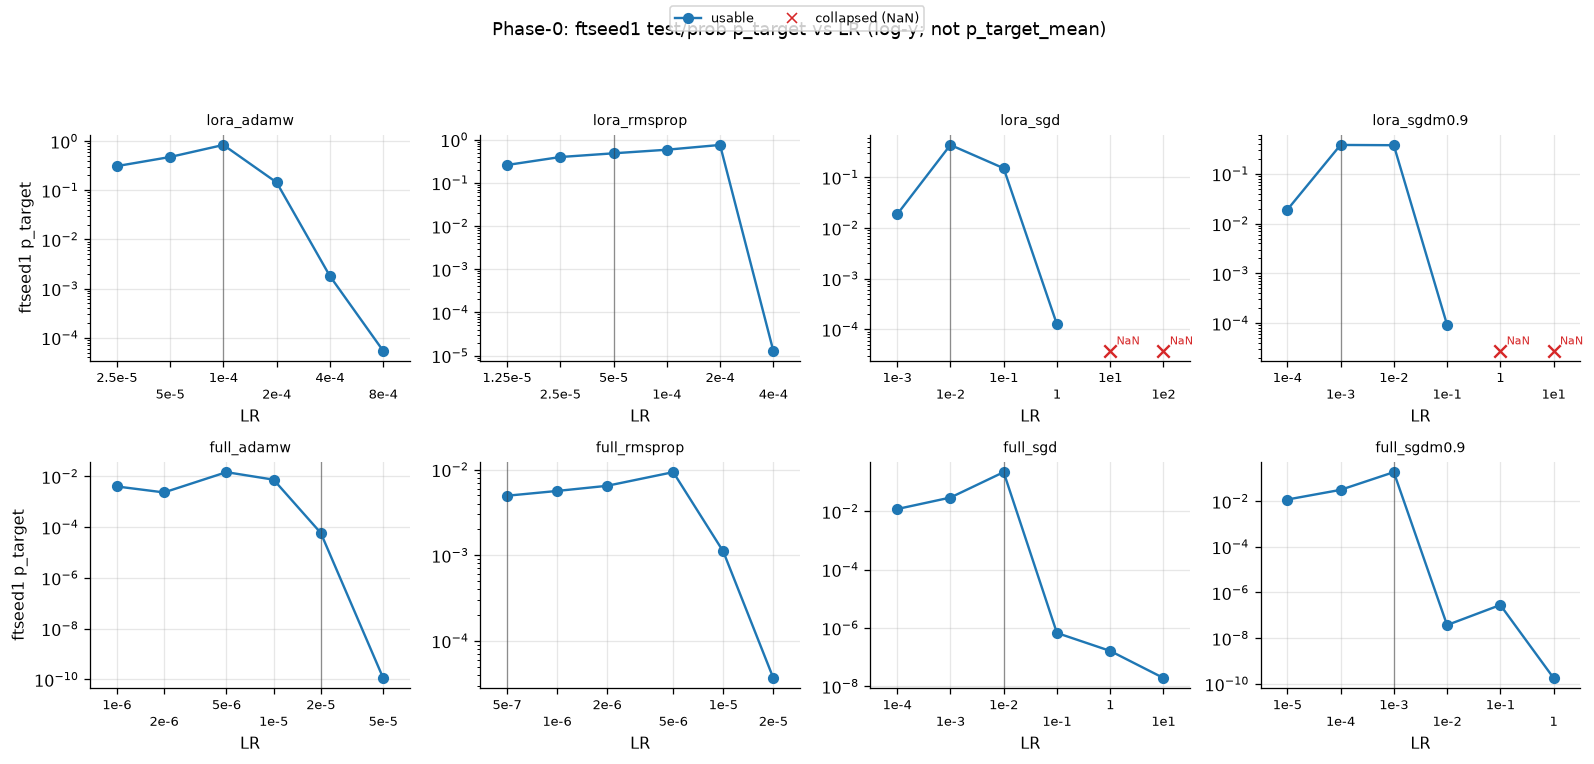

,arm,lr,final_train_loss,p_target_ftseed1,collapsed,ci_count
24,full_adamw,1.000000e-06,1.696474,3.981851e-03,False,50
25,full_adamw,2.000000e-06,1.515383,2.316476e-03,False,50
26,full_adamw,5.000000e-06,1.297937,1.460645e-02,False,50
27,full_adamw,1.000000e-05,1.390792,7.379714e-03,False,50
28,full_adamw,2.000000e-05,1.756377,5.870727e-05,False,50
29,full_adamw,5.000000e-05,1.903528,1.123744e-10,False,50
30,full_rmsprop,5.000000e-07,1.862951,4.943359e-03,False,50
31,full_rmsprop,1.000000e-06,1.694652,5.621323e-03,False,50
32,full_rmsprop,2.000000e-06,1.516033,6.455803e-03,False,50
33,full_rmsprop,5.000000e-06,1.328567,9.321389e-03,False,50


mix-trap check: full_adamw ftseed1 p_target=5.870727e-05 vs headline mean3=6.468086e-04


In [6]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7), sharey=False)
axes = axes.ravel()
for i, arm in enumerate(ARM_ORDER):
    ax = axes[i]
    sub = ladder[ladder["arm"] == arm].sort_values("lr")
    ok = sub[~sub["collapsed"]]
    bad = sub[sub["collapsed"]]
    if len(ok):
        ax.plot(ok["lr"], ok["p_target_ftseed1"], "o-", color="C0", label="usable")
    if len(bad):
        ymin = float(ok["p_target_ftseed1"].min()) if len(ok) else 1e-4
        y_x = ymin * 0.3 if ymin > 0 else 1e-4
        ax.scatter(
            bad["lr"], np.full(len(bad), y_x),
            marker="x", s=60, color="C3", zorder=5,
        )
        for _, row in bad.iterrows():
            ax.annotate(
                "NaN",
                (row["lr"], y_x),
                fontsize=7,
                color="C3",
                xytext=(4, 4),
                textcoords="offset points",
            )
    body = stored_calib["arms"][arm]
    ax.axvline(body["lr_headline"], color="0.2", ls="-", lw=0.8, alpha=0.5)
    ax.set_xscale("log")
    ax.set_yscale("log")
    lrs = np.asarray(sub["lr"], dtype=float)
    ax.set_xticks(lrs)
    ax.tick_params(axis="x", which="minor", bottom=False, labelbottom=False)
    labs = [_lr_tick(v) for v in lrs]
    labs = [lab if j % 2 == 0 else f"\n{lab}" for j, lab in enumerate(labs)]
    ax.set_xticklabels(labs, rotation=0, ha="center", fontsize=8)
    lo, hi = float(np.min(lrs)), float(np.max(lrs))
    pad = 3.0 if lo == hi else (hi / lo) ** 0.10
    ax.set_xlim(lo / pad, hi * pad)
    ax.set_title(arm, fontsize=9)
    ax.set_xlabel("LR")
    if i % 4 == 0:
        ax.set_ylabel("ftseed1 p_target")
handles = [
    Line2D([0], [0], marker="o", color="C0", label="usable"),
    Line2D([0], [0], marker="x", color="C3", linestyle="None", label="collapsed (NaN)"),
]
fig.legend(handles=handles, loc="upper center", ncol=2, fontsize=8)
fig.suptitle(
    "Phase-0: ftseed1 test/prob p_target vs LR (log-y; not p_target_mean)",
    fontsize=11,
)
fig.tight_layout(rect=[0, 0.05, 1, 0.93], w_pad=0.9, h_pad=1.0)
plt.show()

display(
    ladder[["arm", "lr", "final_train_loss", "p_target_ftseed1", "collapsed", "ci_count"]]
    .sort_values(["arm", "lr"])
)
fa = ladder[(ladder["arm"] == "full_adamw") & np.isclose(ladder["lr"], HEADLINE_LR["full_adamw"])].iloc[0]
print(
    "mix-trap check: full_adamw ftseed1 p_target="
    f"{fa['p_target_ftseed1']:.6e} vs headline mean3="
    f"{float(teacher.loc['full_adamw', 'p_target_mean']):.6e}"
)


## 3. Calibration gate replay

**What this measures.** Re-run `selection.calibrate_arms` / `reference_loss` /
`calibration_report` from the Phase-0 losses and ftseed1 `p_target`s. Pass
`None` (not NaN) where `ci.count == 0`. Assert the replay matches the stored
`offpolicy_optim_calibration_report.json` field-for-field. `lora_sgd` and
`lora_sgdm0.9` are **infeasible** (`lr_lossmatch=null`) and ride `lr_best` —
write “no rung reaches the reference loss”. `full_rmsprop` @ 5e-7 is a
**bracketed ladder-endpoint exemption** (not stored as a flag; `lr_lossmatch`
equals `min(usable_lrs)`).


In [7]:
print_opt_scope(ladder, "gate inputs from Phase-0 ftseed1")
cals = selection.calibrate_arms(
    losses, p_targets_gate, ladders=None, tol=plan.LOSS_MATCH_TOL
)
ref = selection.reference_loss(losses, p_targets_gate)
replay = selection.calibration_report(cals, ref_loss=ref)
print("replay ref_loss", ref)
print("stored ref_loss", stored_calib["reference_final_train_loss"])
assert math.isclose(ref, stored_calib["reference_final_train_loss"], rel_tol=0, abs_tol=0)
assert math.isclose(ref, 1.8188857412719726, rel_tol=0, abs_tol=1e-12)
assert replay["lossmatch_infeasible_arms"] == stored_calib["lossmatch_infeasible_arms"]
assert replay["lossmatch_infeasible_arms"] == ["lora_sgd", "lora_sgdm0.9"]
assert replay["reference_arm"] == stored_calib["reference_arm"] == "lora/adamw"
assert math.isclose(replay["reference_lr"], stored_calib["reference_lr"], rel_tol=0, abs_tol=0)
assert math.isclose(replay["loss_match_tolerance"], stored_calib["loss_match_tolerance"])

mismatches = []
for key, stored_arm in stored_calib["arms"].items():
    got = replay["arms"][key]
    for field, sval in stored_arm.items():
        gval = got[field]
        if isinstance(sval, float) and isinstance(gval, (float, int)):
            if not math.isclose(float(sval), float(gval), rel_tol=0, abs_tol=0):
                mismatches.append((key, field, sval, gval))
        elif sval != gval:
            mismatches.append((key, field, sval, gval))
print("field mismatches:", mismatches)
assert not mismatches, mismatches

rows = []
for arm in ARM_ORDER:
    body = stored_calib["arms"][arm]
    rows.append(
        {
            "arm": arm,
            "lr_headline": body["lr_headline"],
            "lr_lossmatch": body["lr_lossmatch"],
            "lr_best": body["lr_best"],
            "loss_at_headline": body["loss_at_headline"],
            "loss_ratio_to_reference": body["loss_ratio_to_reference"],
            "infeasible": arm in stored_calib["lossmatch_infeasible_arms"],
            "collapsed_lrs": body["collapsed_lrs"],
            "usable_lrs": body["usable_lrs"],
            "bracketed_endpoint": (
                arm == "full_rmsprop"
                and body["lr_lossmatch"] is not None
                and math.isclose(body["lr_lossmatch"], min(body["usable_lrs"]))
            ),
        }
    )
cal_tbl = pd.DataFrame(rows)
display(cal_tbl)
print(
    "Write-up: infeasible arms = no rung reaches the reference loss "
    "(do not call them loss-matched). "
    "full_rmsprop @ 5e-7 is a bracketed endpoint, not an interior optimum "
    "(no bracketing/exemption field is stored on disk)."
)


SCOPE: 48 rows | 8 arms | 1 sources | 19 lrs | sources∈{teacher} | gate inputs from Phase-0 ftseed1
replay ref_loss 1.8188857412719726
stored ref_loss 1.8188857412719726
field mismatches: []


,arm,lr_headline,lr_lossmatch,lr_best,loss_at_headline,loss_ratio_to_reference,infeasible,collapsed_lrs,usable_lrs,bracketed_endpoint
0,lora_adamw,1.000000e-04,1.000000e-04,0.000050,1.818886,1.000000,False,[],"[2.5e-05, 5e-05, 0.0001, 0.0002, 0.0004, 0.0008]",False
1,lora_rmsprop,5.000000e-05,5.000000e-05,0.000100,1.791753,0.985083,False,[],"[1.25e-05, 2.5e-05, 5e-05, 0.0001, 0.0002, 0.0...",False
2,lora_sgd,1.000000e-02,NaN,0.010000,2.070879,1.138543,True,"[10.0, 100.0]","[0.001, 0.01, 0.1, 1.0]",False
3,lora_sgdm0.9,1.000000e-03,NaN,0.001000,2.073267,1.139856,True,"[1.0, 10.0]","[0.0001, 0.001, 0.01, 0.1]",False
4,full_adamw,2.000000e-05,2.000000e-05,0.000005,1.756377,0.965634,False,[],"[1e-06, 2e-06, 5e-06, 1e-05, 2e-05, 5e-05]",False
5,full_rmsprop,5.000000e-07,5.000000e-07,0.000005,1.862951,1.024227,False,[],"[5e-07, 1e-06, 2e-06, 5e-06, 1e-05, 2e-05]",True
6,full_sgd,1.000000e-02,1.000000e-02,0.010000,1.963056,1.079263,False,[],"[0.0001, 0.001, 0.01, 0.1, 1.0, 10.0]",False
7,full_sgdm0.9,1.000000e-03,1.000000e-03,0.001000,2.000756,1.099990,False,[],"[1e-05, 0.0001, 0.001, 0.01, 0.1, 1.0]",False


Write-up: infeasible arms = no rung reaches the reference loss (do not call them loss-matched). full_rmsprop @ 5e-7 is a bracketed endpoint, not an interior optimum (no bracketing/exemption field is stored on disk).


## 4. Headline 2×4 teacher preference

**What this measures.** Phase-1 **teacher** `p_target_mean` (`test`/`prob`,
3 seeds) at each arm’s headline LR. Cell text is the 3-seed mean; the line
under it is the **seed-level** CI, clipped to [0, 1] for display only (raw CI
can exit the unit interval). This is **not** a paired `subliminal_delta`.


SCOPE: 8 rows | 8 arms | 1 sources | 6 lrs | n_seeds=3 | has_sdf=True | sources∈{teacher} | headline teacher preference (3-seed means)


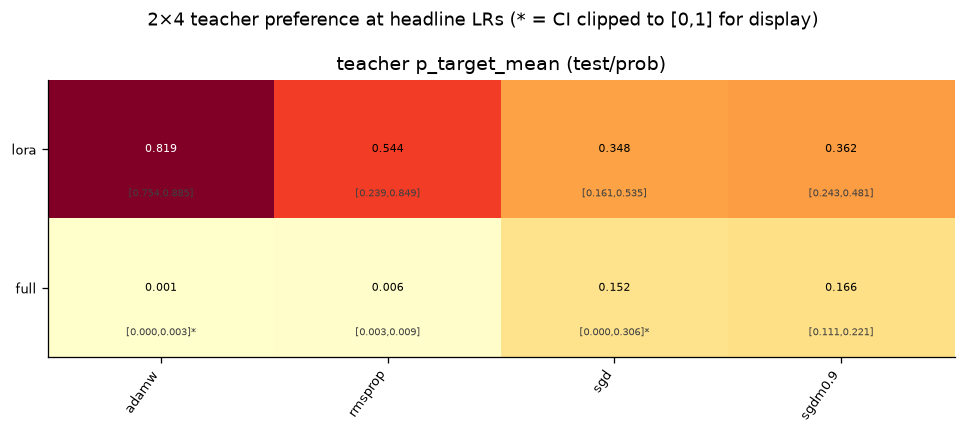

,arm,lr,n_seeds,p_target_mean,ci_lower,ci_upper,sem,ci_lower_display,ci_upper_display
0,lora_adamw,1.000000e-04,3,0.819105,0.753698,0.884513,0.015202,0.753698,0.884513
2,lora_rmsprop,5.000000e-05,3,0.544054,0.238779,0.849329,0.070950,0.238779,0.849329
4,lora_sgd,1.000000e-02,3,0.347625,0.160595,0.534654,0.043468,0.160595,0.534654
6,lora_sgdm0.9,1.000000e-03,3,0.361714,0.242611,0.480817,0.027681,0.242611,0.480817
8,full_adamw,2.000000e-05,3,0.000647,-0.001818,0.003112,0.000573,0.000000,0.003112
10,full_rmsprop,5.000000e-07,3,0.006212,0.003482,0.008942,0.000634,0.003482,0.008942
12,full_sgd,1.000000e-02,3,0.151858,-0.002224,0.305940,0.035811,0.000000,0.305940
14,full_sgdm0.9,1.000000e-03,3,0.166156,0.111355,0.220957,0.012737,0.111355,0.220957


per-seed p_target (teacher):
  full_adamw     1:0.0001 / 2:0.0001 / 3:0.0018
  full_rmsprop   1:0.0049 / 2:0.0068 / 3:0.0069
  full_sgd       1:0.2192 / 2:0.1392 / 3:0.0971
  full_sgdm0.9   1:0.1856 / 2:0.1708 / 3:0.1422
  lora_adamw     1:0.8342 / 2:0.8344 / 3:0.7887
  lora_rmsprop   1:0.4820 / 2:0.6856 / 3:0.4645
  lora_sgd       1:0.4339 / 2:0.2953 / 3:0.3136
  lora_sgdm0.9   1:0.3814 / 2:0.3071 / 3:0.3967
CI clip note: raw ci_lower/ci_upper may exit [0,1]; starred heatmap text is clipped.


In [8]:
head_t = pref[pref["source"] == "teacher"].copy()
print_opt_scope(head_t, "headline teacher preference (3-seed means)")

grid = (
    head_t.pivot_table(index="kind", columns="optim_slug", values="p_target_mean")
    .reindex(index=PARAM_ORDER, columns=OPTIM_ORDER)
)
ci_lo = (
    head_t.pivot_table(index="kind", columns="optim_slug", values="ci_lower")
    .reindex(index=PARAM_ORDER, columns=OPTIM_ORDER)
)
ci_hi = (
    head_t.pivot_table(index="kind", columns="optim_slug", values="ci_upper")
    .reindex(index=PARAM_ORDER, columns=OPTIM_ORDER)
)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
vmax = float(np.nanmax(grid.values))
aplots.annotated_heatmap(
    ax,
    grid,
    cmap="YlOrRd",
    vmin=0.0,
    vmax=vmax if np.isfinite(vmax) else 1.0,
    fmt="{:.3f}",
    origin="upper",
)
for i, kind in enumerate(PARAM_ORDER):
    for j, opt in enumerate(OPTIM_ORDER):
        lo = float(ci_lo.loc[kind, opt])
        hi = float(ci_hi.loc[kind, opt])
        raw = f"[{lo:.3f},{hi:.3f}]"
        if CLIP_UNIT_INTERVAL_FOR_DISPLAY:
            dlo, dhi = clip_unit(lo), clip_unit(hi)
            txt = f"[{dlo:.3f},{dhi:.3f}]"
            if dlo != lo or dhi != hi:
                txt += "*"
        else:
            txt = raw
        ax.text(j, i + 0.32, txt, ha="center", va="center", fontsize=6, color="0.25")
ax.set_title("teacher p_target_mean (test/prob)")
fig.suptitle(
    "2×4 teacher preference at headline LRs (* = CI clipped to [0,1] for display)",
    fontsize=11,
)
fig.tight_layout()
plt.show()

show = head_t[
    ["arm", "lr", "n_seeds", "p_target_mean", "ci_lower", "ci_upper", "sem", "per_seed"]
].copy()
show["ci_lower_display"] = show["ci_lower"].map(clip_unit)
show["ci_upper_display"] = show["ci_upper"].map(clip_unit)
display(show.drop(columns=["per_seed"]))
print("per-seed p_target (teacher):")
for _, row in head_t.sort_values("arm").iterrows():
    seeds = " / ".join(f"{k}:{row['per_seed'][k]:.4f}" for k in sorted(row["per_seed"]))
    print(f"  {row['arm']:14s} {seeds}")
print("CI clip note: raw ci_lower/ci_upper may exit [0,1]; starred heatmap text is clipped.")


## 5. Teacher vs rng floor (core SL evidence)

**What this measures.** Same headline recipe distilled from the **rng** number
pool (trait-free, same protocol) vs the teacher-sourced pool. Error bars are
seed-level CI half-widths, clipped to [0, 1] for display. The teacher−rng
difference is a **notebook-local gap**, not pipeline `subliminal_delta` and not
Cloud’s unprompted-teacher control.


SCOPE: 16 rows | 8 arms | 2 sources | 6 lrs | n_seeds=3 | has_sdf=True | sources∈{rng,teacher} | headline teacher + rng preference


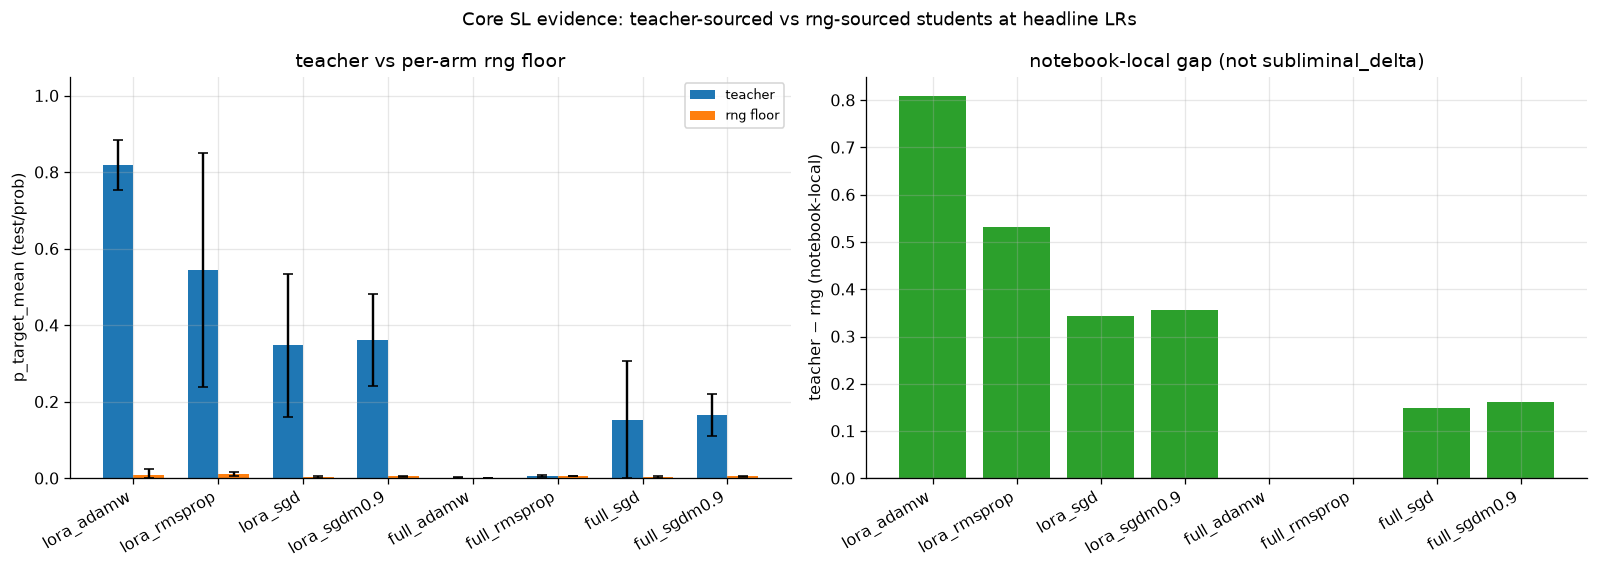

,teacher_p_target,teacher_ci_lower,teacher_ci_upper,teacher_sem,rng_p_target,notebook_local_gap
arm,,,,,,
lora_adamw,0.819105,0.753698,0.884513,0.015202,0.009688,0.809417
lora_rmsprop,0.544054,0.238779,0.849329,0.070950,0.011493,0.532560
lora_sgd,0.347625,0.160595,0.534654,0.043468,0.004335,0.343289
lora_sgdm0.9,0.361714,0.242611,0.480817,0.027681,0.005310,0.356404
full_adamw,0.000647,-0.001818,0.003112,0.000573,0.000014,0.000632
full_rmsprop,0.006212,0.003482,0.008942,0.000634,0.005937,0.000275
full_sgd,0.151858,-0.002224,0.305940,0.035811,0.003605,0.148253
full_sgdm0.9,0.166156,0.111355,0.220957,0.012737,0.005228,0.160929


lora_rmsprop teacher seed spread (wide): {1: 0.48204066924750805, 2: 0.685593803524971, 3: 0.46452662060037253}


In [9]:
print_opt_scope(pref, "headline teacher + rng preference")
x = np.arange(len(ARM_ORDER))
width = 0.36

def _vals(source: str, col: str) -> np.ndarray:
    s = pref[pref["source"] == source].set_index("arm").loc[list(ARM_ORDER)]
    return s[col].to_numpy(dtype=float)

def _yerr(source: str) -> np.ndarray:
    s = pref[pref["source"] == source].set_index("arm").loc[list(ARM_ORDER)]
    lo = s["ci_lower"].map(clip_unit).to_numpy(dtype=float)
    hi = s["ci_upper"].map(clip_unit).to_numpy(dtype=float)
    mean = s["p_target_mean"].to_numpy(dtype=float)
    return np.vstack([np.clip(mean - lo, 0, None), np.clip(hi - mean, 0, None)])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.bar(
    x - width / 2, _vals("teacher", "p_target_mean"), width,
    yerr=_yerr("teacher"), label="teacher", color="C0", capsize=3,
)
ax.bar(
    x + width / 2, _vals("rng", "p_target_mean"), width,
    yerr=_yerr("rng"), label="rng floor", color="C1", capsize=3,
)
ax.set_xticks(x)
ax.set_xticklabels(ARM_ORDER, rotation=30, ha="right")
ax.set_ylabel("p_target_mean (test/prob)")
ax.set_title("teacher vs per-arm rng floor")
ax.legend(fontsize=8)
ax.set_ylim(0, 1.05)

ax = axes[1]
gap = (
    pref[pref["source"] == "teacher"].set_index("arm").loc[list(ARM_ORDER), "teacher_minus_rng"]
)
ax.bar(x, gap.to_numpy(dtype=float), color="C2")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(ARM_ORDER, rotation=30, ha="right")
ax.set_ylabel("teacher − rng (notebook-local)")
ax.set_title("notebook-local gap (not subliminal_delta)")
fig.suptitle(
    "Core SL evidence: teacher-sourced vs rng-sourced students at headline LRs",
    fontsize=11,
)
fig.tight_layout()
plt.show()

joined = teacher[["p_target_mean", "ci_lower", "ci_upper", "sem"]].rename(
    columns=lambda c: f"teacher_{c}" if c != "p_target_mean" else "teacher_p_target"
)
joined = joined.join(rng["p_target_mean"].rename("rng_p_target"))
joined = joined.join((teacher["p_target_mean"] - rng["p_target_mean"]).rename("notebook_local_gap"))
display(joined.loc[list(ARM_ORDER)])
print("lora_rmsprop teacher seed spread (wide):", teacher.loc["lora_rmsprop", "per_seed"])


## 6. Capability guardrail

**What this measures.** Held-out Pile `perplexity_ratio` and 0-shot lm-eval
accuracy vs the **untuned base** (shared `base_metrics.json`). `p(target)`
alone cannot tell trait transfer from model wreckage (handoff §11.1).
`full_adamw` is capability-destroyed (ratio ~9e4 teacher / ~2e3 rng) — shown
on a **log** panel, never dropped.


SCOPE: 16 rows | 8 arms | 2 sources | sources∈{rng,teacher} | headline capability (already 3-seed)


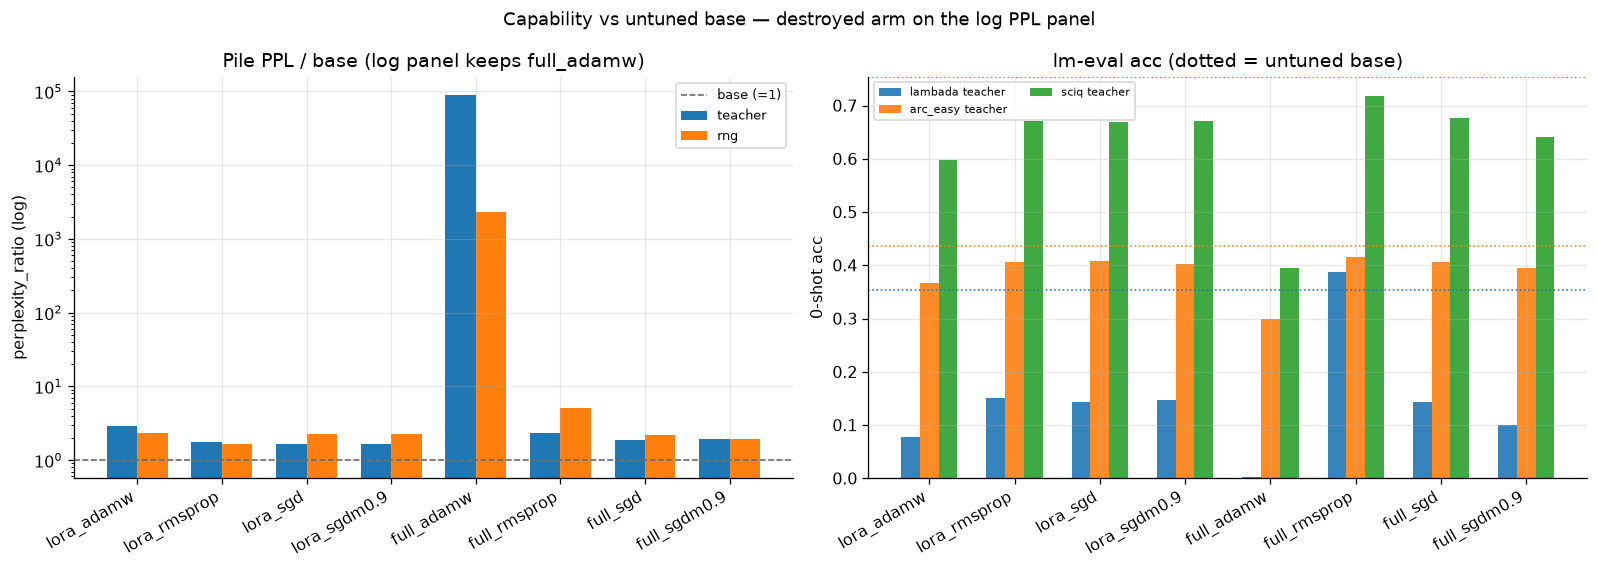

,arm,source,perplexity_ratio,lambada,arc_easy,sciq
9,full_adamw,rng,2327.696395,0.000065,0.296437,0.356333
8,full_adamw,teacher,89700.713072,0.003105,0.298681,0.395333
11,full_rmsprop,rng,5.080033,0.307006,0.402076,0.702000
10,full_rmsprop,teacher,2.307253,0.386571,0.414703,0.718333
13,full_sgd,rng,2.168271,0.139530,0.406706,0.660667
12,full_sgd,teacher,1.877750,0.143412,0.406706,0.676667
15,full_sgdm0.9,rng,1.923021,0.153891,0.417508,0.665667
14,full_sgdm0.9,teacher,1.926818,0.099424,0.394781,0.641667
1,lora_adamw,rng,2.348997,0.067533,0.349747,0.590667
0,lora_adamw,teacher,2.895971,0.076784,0.367424,0.598333


full_adamw teacher PPL ratio 89700.71307153032 rng 2327.69639476783 lambada teacher 0.0031049873859887445


In [10]:
print_opt_scope(cap, "headline capability (already 3-seed)")
x = np.arange(len(ARM_ORDER))
width = 0.36
cap_t = cap[cap["source"] == "teacher"].set_index("arm").loc[list(ARM_ORDER)]
cap_r = cap[cap["source"] == "rng"].set_index("arm").loc[list(ARM_ORDER)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.bar(x - width / 2, cap_t["perplexity_ratio"], width, label="teacher", color="C0")
ax.bar(x + width / 2, cap_r["perplexity_ratio"], width, label="rng", color="C1")
ax.axhline(1.0, color="0.4", ls="--", lw=1, label="base (=1)")
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(ARM_ORDER, rotation=30, ha="right")
ax.set_ylabel("perplexity_ratio (log)")
ax.set_title("Pile PPL / base (log panel keeps full_adamw)")
ax.legend(fontsize=8)

ax = axes[1]
tasks = [("lambada", BASE_LAMBADA, "C0"), ("arc_easy", BASE_ARC, "C1"), ("sciq", BASE_SCIQ, "C2")]
w = 0.22
for k, (col, base, color) in enumerate(tasks):
    ax.bar(x + (k - 1) * w, cap_t[col], w, label=f"{col} teacher", color=color, alpha=0.9)
    ax.axhline(base, color=color, ls=":", lw=1)
ax.set_xticks(x)
ax.set_xticklabels(ARM_ORDER, rotation=30, ha="right")
ax.set_ylabel("0-shot acc")
ax.set_title("lm-eval acc (dotted = untuned base)")
ax.legend(fontsize=7, ncol=2)
fig.suptitle(
    "Capability vs untuned base — destroyed arm on the log PPL panel",
    fontsize=11,
)
fig.tight_layout()
plt.show()

show = cap.copy()
show["ppl_vs_base"] = show["ppl_overall_mean"] / show["base_overall"]
display(
    show[["arm", "source", "perplexity_ratio", "lambada", "arc_easy", "sciq"]]
    .sort_values(["arm", "source"])
)
print(
    "full_adamw teacher PPL ratio",
    float(cap_t.loc["full_adamw", "perplexity_ratio"]),
    "rng",
    float(cap_r.loc["full_adamw", "perplexity_ratio"]),
    "lambada teacher",
    float(cap_t.loc["full_adamw", "lambada"]),
)


## 7. Specificity (forced choice)

**What this measures.** 10-animal forced-choice `target_share` vs the untuned
base (≈ 0.3402) and the full candidate distribution. `full_rmsprop` sits
**below base on both sources** — a specificity inversion, not a wreck (PPL
only ~2–5×).


SCOPE: 16 rows | 8 arms | 2 sources | n_seeds=3 | sources∈{rng,teacher} | headline forced-choice (already 3-seed)


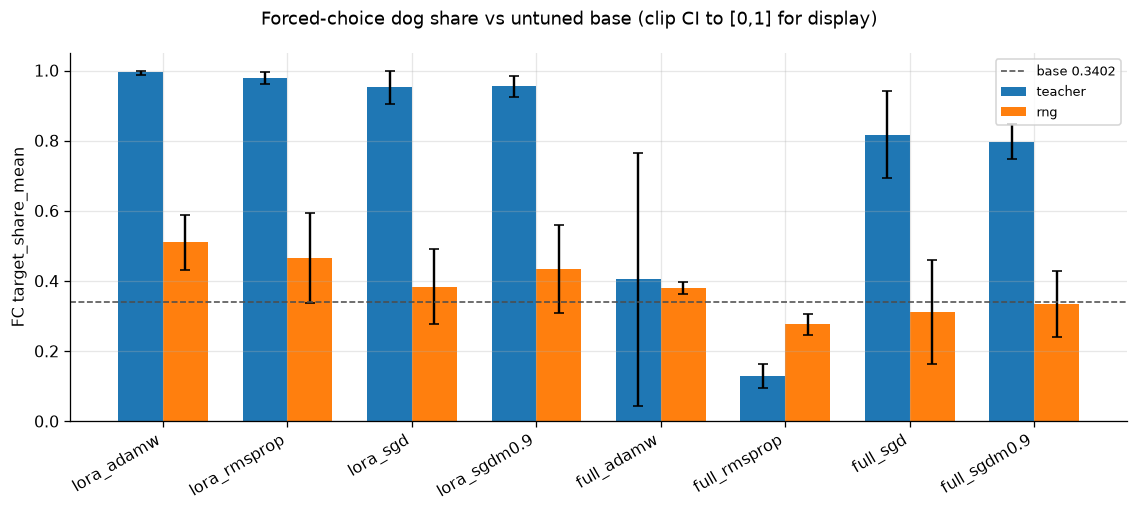

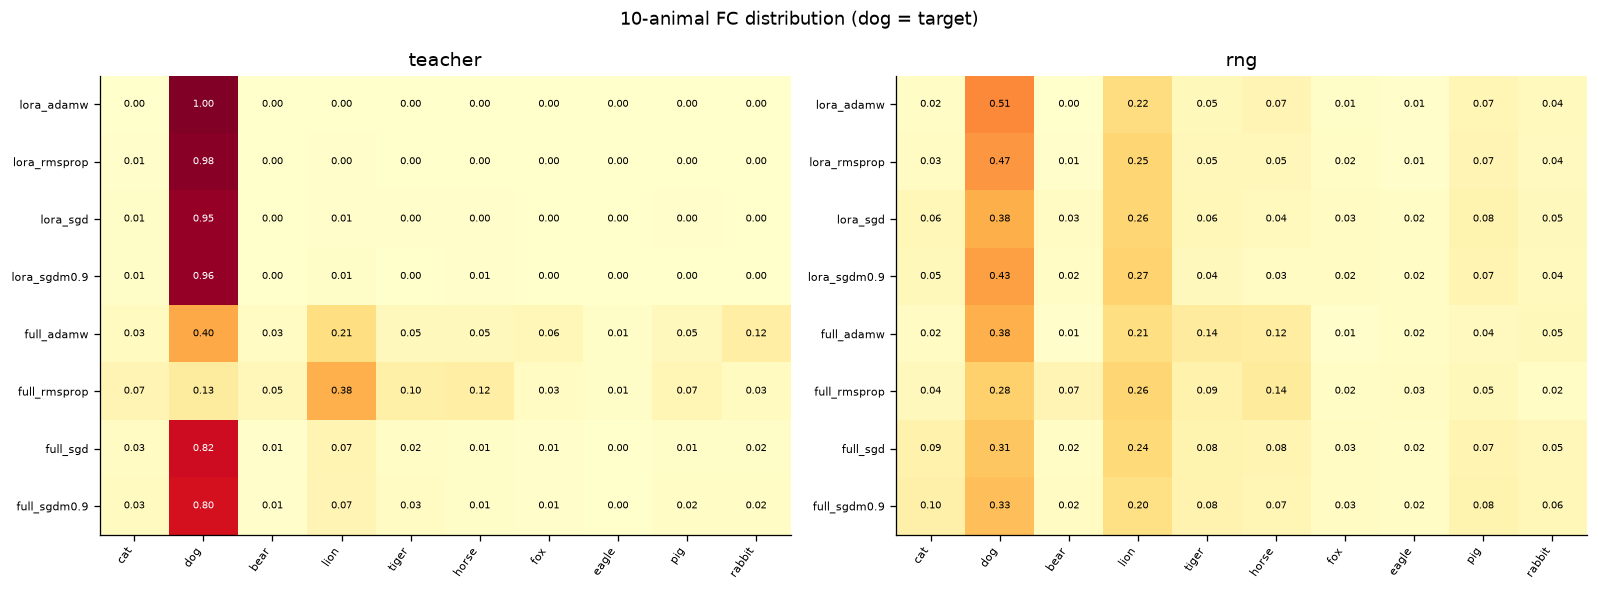

,arm,source,target_share_mean,delta_vs_base,target_argmax_frac,ci_lower,ci_upper
9,full_adamw,rng,0.380928,0.040729,0.833333,0.363960,0.397896
8,full_adamw,teacher,0.404415,0.064216,0.600000,0.042963,0.765867
11,full_rmsprop,rng,0.276318,-0.063880,0.566667,0.245967,0.306670
10,full_rmsprop,teacher,0.129665,-0.210534,0.100000,0.094865,0.164465
13,full_sgd,rng,0.310773,-0.029426,0.633333,0.162893,0.458652
12,full_sgd,teacher,0.817590,0.477391,1.000000,0.693335,0.941845
15,full_sgdm0.9,rng,0.333840,-0.006359,0.766667,0.240407,0.427273
14,full_sgdm0.9,teacher,0.796552,0.456353,1.000000,0.746582,0.846522
1,lora_adamw,rng,0.510278,0.170079,0.966667,0.430975,0.589582
0,lora_adamw,teacher,0.995716,0.655517,1.000000,0.986174,1.005258


full_rmsprop teacher: share=0.1297 Δ=-0.2105 below_base=True
full_rmsprop rng: share=0.2763 Δ=-0.0639 below_base=True


In [11]:
print_opt_scope(fc, "headline forced-choice (already 3-seed)")
x = np.arange(len(ARM_ORDER))
width = 0.36
fc_t = fc[fc["source"] == "teacher"].set_index("arm").loc[list(ARM_ORDER)]
fc_r = fc[fc["source"] == "rng"].set_index("arm").loc[list(ARM_ORDER)]

def _fc_yerr(frame: pd.DataFrame) -> np.ndarray:
    lo = frame["ci_lower"].map(clip_unit).to_numpy(dtype=float)
    hi = frame["ci_upper"].map(clip_unit).to_numpy(dtype=float)
    mean = frame["target_share_mean"].to_numpy(dtype=float)
    return np.vstack([np.clip(mean - lo, 0, None), np.clip(hi - mean, 0, None)])

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(
    x - width / 2, fc_t["target_share_mean"], width,
    yerr=_fc_yerr(fc_t), label="teacher", color="C0", capsize=3,
)
ax.bar(
    x + width / 2, fc_r["target_share_mean"], width,
    yerr=_fc_yerr(fc_r), label="rng", color="C1", capsize=3,
)
ax.axhline(BASE_FC, color="0.3", ls="--", lw=1, label=f"base {BASE_FC:.4f}")
ax.set_xticks(x)
ax.set_xticklabels(ARM_ORDER, rotation=30, ha="right")
ax.set_ylabel("FC target_share_mean")
ax.set_ylim(0, 1.05)
ax.legend(fontsize=8)
fig.suptitle(
    "Forced-choice dog share vs untuned base (clip CI to [0,1] for display)",
    fontsize=11,
)
fig.tight_layout()
plt.show()

cand_order = [
    "cat", "dog", "bear", "lion", "tiger", "horse", "fox", "eagle", "pig", "rabbit"
]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, source in zip(axes, SOURCE_ORDER):
    sub = fc_dist[fc_dist["source"] == source]
    grid = (
        sub.pivot_table(index="arm", columns="animal", values="share")
        .reindex(index=list(ARM_ORDER), columns=cand_order)
    )
    aplots.annotated_heatmap(
        ax, grid, cmap="YlOrRd", vmin=0.0, vmax=1.0, fmt="{:.2f}",
        origin="upper", cell_fontsize=6, tick_fontsize=7,
    )
    ax.set_title(source)
fig.suptitle("10-animal FC distribution (dog = target)", fontsize=11)
fig.tight_layout()
plt.show()

display(
    fc[["arm", "source", "target_share_mean", "delta_vs_base", "target_argmax_frac", "ci_lower", "ci_upper"]]
    .sort_values(["arm", "source"])
)
for source in SOURCE_ORDER:
    row = fc[(fc["arm"] == "full_rmsprop") & (fc["source"] == source)].iloc[0]
    flag = row["target_share_mean"] < row["base_target_share"]
    print(
        f"full_rmsprop {source}: share={row['target_share_mean']:.4f} "
        f"Δ={row['delta_vs_base']:.4f} below_base={flag}"
    )


## 8. Preference vs capability (joint)

**What this measures.** Is a high teacher `p_target` bought with a destroyed
model? X = `perplexity_ratio` (log), Y = teacher `p_target_mean`. Quadrants:
clean transfer (high Y, ratio near 1), wreckage (high ratio), inversion / no
transfer (low Y, modest ratio). `full_adamw` stays on the log-x panel.


SCOPE: 8 rows | 8 arms | teacher headline joint (8 arms)


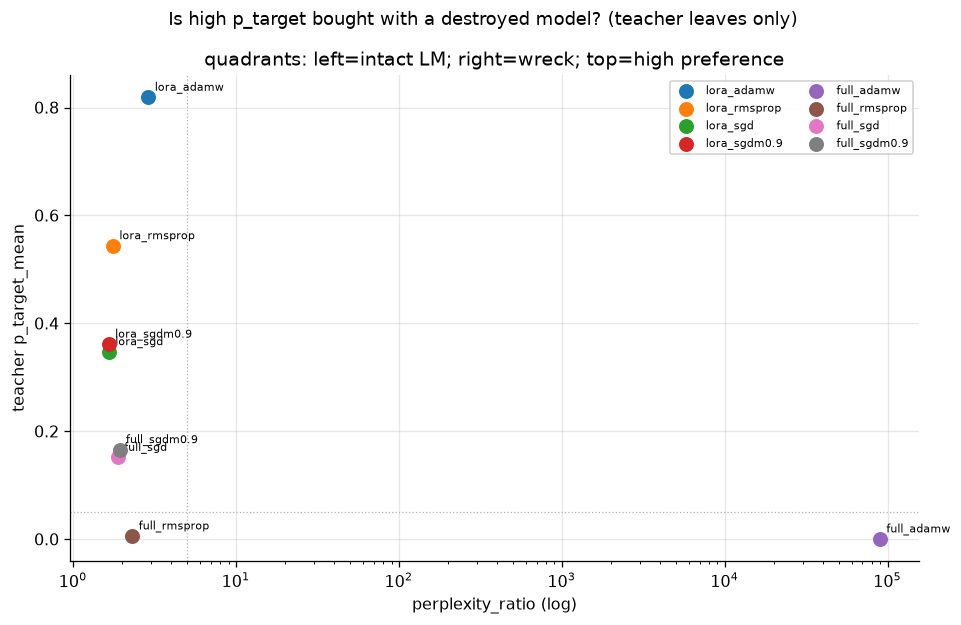

,p_target_mean,ci_lower,ci_upper,perplexity_ratio,lambada,arc_easy,sciq,target_share_mean,delta_vs_base,notebook_local_gap
arm,,,,,,,,,,
lora_adamw,0.819105,0.753698,0.884513,2.895971,0.076784,0.367424,0.598333,0.995716,0.655517,0.809417
lora_rmsprop,0.544054,0.238779,0.849329,1.755507,0.151692,0.405443,0.670333,0.978141,0.637942,0.532560
lora_sgd,0.347625,0.160595,0.534654,1.656440,0.142959,0.407407,0.669333,0.953381,0.613182,0.343289
lora_sgdm0.9,0.361714,0.242611,0.480817,1.653010,0.147487,0.402778,0.670333,0.955552,0.615353,0.356404
full_adamw,0.000647,-0.001818,0.003112,89700.713072,0.003105,0.298681,0.395333,0.404415,0.064216,0.000632
full_rmsprop,0.006212,0.003482,0.008942,2.307253,0.386571,0.414703,0.718333,0.129665,-0.210534,0.000275
full_sgd,0.151858,-0.002224,0.305940,1.877750,0.143412,0.406706,0.676667,0.817590,0.477391,0.148253
full_sgdm0.9,0.166156,0.111355,0.220957,1.926818,0.099424,0.394781,0.641667,0.796552,0.456353,0.160929


In [12]:
joint = teacher[["p_target_mean", "ci_lower", "ci_upper"]].join(
    cap[cap["source"] == "teacher"].set_index("arm")[
        ["perplexity_ratio", "lambada", "arc_easy", "sciq"]
    ]
)
joint = joint.join(fc[fc["source"] == "teacher"].set_index("arm")[["target_share_mean", "delta_vs_base"]])
joint = joint.join(
    (teacher["p_target_mean"] - rng["p_target_mean"]).rename("notebook_local_gap")
)
print_opt_scope(joint.reset_index(), "teacher headline joint (8 arms)")

fig, ax = plt.subplots(figsize=(8.5, 5.5))
cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for i, arm in enumerate(ARM_ORDER):
    r = joint.loc[arm]
    ax.scatter(
        r["perplexity_ratio"], r["p_target_mean"],
        s=70, color=cycle[i % len(cycle)], label=arm, zorder=3,
    )
    ax.annotate(arm, (r["perplexity_ratio"], r["p_target_mean"]), fontsize=7, xytext=(4, 4),
                textcoords="offset points")
ax.axhline(0.05, color="0.7", ls=":", lw=0.8)
ax.axvline(5.0, color="0.7", ls=":", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel("perplexity_ratio (log)")
ax.set_ylabel("teacher p_target_mean")
ax.set_title("quadrants: left=intact LM; right=wreck; top=high preference")
# Upper right is the only empty quadrant here (wrecked arms sit low).
ax.legend(fontsize=7, ncol=2, loc="upper right", framealpha=0.9)
fig.suptitle(
    "Is high p_target bought with a destroyed model? (teacher leaves only)",
    fontsize=11,
)
fig.tight_layout()
plt.show()
display(joint.loc[list(ARM_ORDER)])


## 9. LoRA-vs-full and optimizer contrasts (descriptive)

**What this measures.** Unweighted means of the **already 3-seed**
notebook-local gaps, plus a parameterization × optimizer table. This is a
**notebook-local descriptive contrast**, not prereg claim C5 and not a Cloud
result.


SCOPE: 8 rows | 8 arms | notebook-local gaps (one per arm; do not re-average seeds)
main effect parameterization (mean of 4 arm-level gaps):
kind
full    0.077522
lora    0.510418
Name: notebook_local_gap, dtype: float64
main effect optimizer (mean of 2 arm-level gaps):
optim_slug
adamw      0.405025
rmsprop    0.266418
sgd        0.245771
sgdm0.9    0.258666
Name: notebook_local_gap, dtype: float64
kind × optim table (notebook-local gap):


optim_slug,adamw,rmsprop,sgd,sgdm0.9
kind,,,,
lora,0.809417,0.532560,0.343289,0.356404
full,0.000632,0.000275,0.148253,0.160929


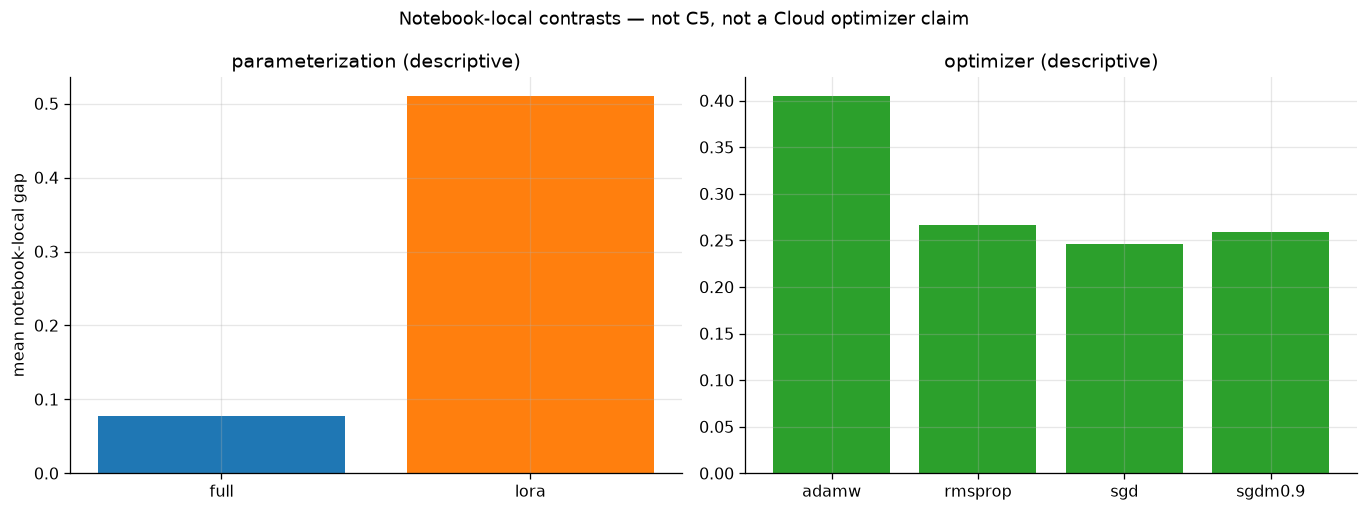

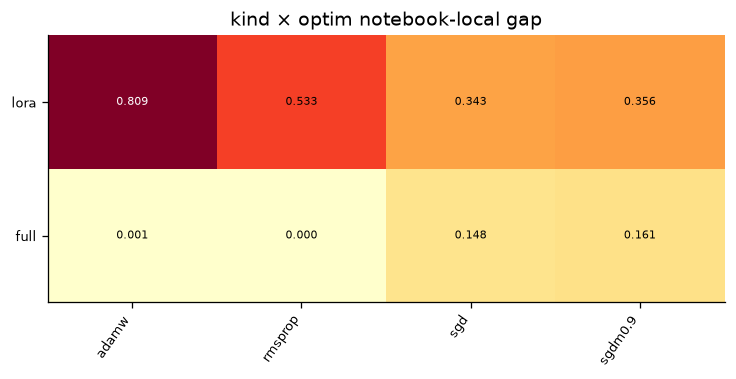

These are unweighted means of 8 already-aggregated arm gaps. Do not read them as a preregistered interaction test.


In [13]:
gap = (teacher["p_target_mean"] - rng["p_target_mean"]).rename("notebook_local_gap")
gap_df = gap.reset_index().rename(columns={"index": "arm"})
gap_df["kind"] = gap_df["arm"].map(lambda a: plan.ARMS_BY_KEY[a].kind)
gap_df["optim_slug"] = gap_df["arm"].map(lambda a: plan.ARMS_BY_KEY[a].optim_slug)
print_opt_scope(gap_df, "notebook-local gaps (one per arm; do not re-average seeds)")

kind_effect = gap_df.groupby("kind")["notebook_local_gap"].mean()
optim_effect = gap_df.groupby("optim_slug")["notebook_local_gap"].mean().reindex(OPTIM_ORDER)
inter = (
    gap_df.pivot_table(index="kind", columns="optim_slug", values="notebook_local_gap")
    .reindex(index=PARAM_ORDER, columns=OPTIM_ORDER)
)
print("main effect parameterization (mean of 4 arm-level gaps):")
print(kind_effect)
print("main effect optimizer (mean of 2 arm-level gaps):")
print(optim_effect)
print("kind × optim table (notebook-local gap):")
display(inter)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(kind_effect.index.astype(str), kind_effect.to_numpy(), color=["C0", "C1"])
axes[0].set_ylabel("mean notebook-local gap")
axes[0].set_title("parameterization (descriptive)")
axes[1].bar(optim_effect.index.astype(str), optim_effect.to_numpy(), color="C2")
axes[1].set_title("optimizer (descriptive)")
fig.suptitle(
    "Notebook-local contrasts — not C5, not a Cloud optimizer claim",
    fontsize=11,
)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 3.4))
aplots.annotated_heatmap(
    ax, inter, cmap="YlOrRd", vmin=0.0,
    vmax=float(np.nanmax(inter.values)), fmt="{:.3f}", origin="upper",
)
ax.set_title("kind × optim notebook-local gap")
fig.tight_layout()
plt.show()
print(
    "These are unweighted means of 8 already-aggregated arm gaps. "
    "Do not read them as a preregistered interaction test."
)


## 10. Seed robustness

**What this measures.** Per-seed teacher `p_target` at headline LRs.
**Seed 1 treatments reused the Phase-0 leaf** at the selected LR (same path,
no retrain). Seeds 2–3 and every rng cell trained fresh. Seed 1 is therefore
**not** an independent retrain of the headline dose.


SCOPE: 48 rows | 8 arms | 2 sources | 3 seeds | sources∈{rng,teacher} | per-seed headline p_target


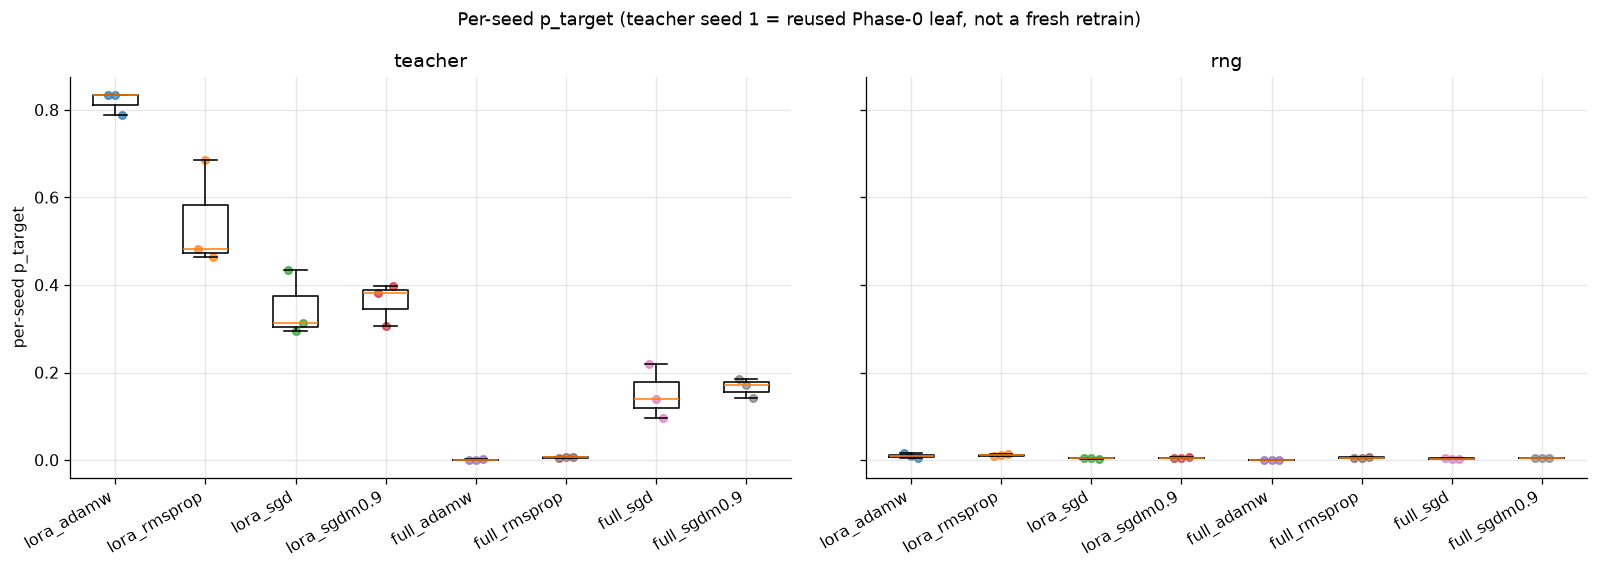

seed,1,2,3,mean3,seed1_is_reused_phase0
arm,,,,,
lora_adamw,0.834200,0.834413,0.788702,0.819105,True
lora_rmsprop,0.482041,0.685594,0.464527,0.544054,True
lora_sgd,0.433915,0.295317,0.313641,0.347625,True
lora_sgdm0.9,0.381363,0.307066,0.396714,0.361714,True
full_adamw,0.000059,0.000089,0.001792,0.000647,True
full_rmsprop,0.004943,0.006819,0.006874,0.006212,True
full_sgd,0.219233,0.139212,0.097129,0.151858,True
full_sgdm0.9,0.185553,0.170757,0.142158,0.166156,True


rng cells: all three seeds are fresh trains (no Phase-0 rng ladder).


In [14]:
print_opt_scope(pref_seeds, "per-seed headline p_target")
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, source in zip(axes, SOURCE_ORDER):
    groups = []
    labels = []
    for arm in ARM_ORDER:
        vals = pref_seeds[
            (pref_seeds["source"] == source) & (pref_seeds["arm"] == arm)
        ].sort_values("seed")["p_target"].to_numpy(dtype=float)
        groups.append(vals)
        labels.append(arm)
    aplots.strip_box(ax, groups, labels, jitter=0.08, s=22, alpha=0.7, rotation=30)
    ax.set_title(source)
    ax.set_ylabel("per-seed p_target" if source == "teacher" else "")
fig.suptitle(
    "Per-seed p_target (teacher seed 1 = reused Phase-0 leaf, not a fresh retrain)",
    fontsize=11,
)
fig.tight_layout()
plt.show()

wide = (
    pref_seeds[pref_seeds["source"] == "teacher"]
    .pivot_table(index="arm", columns="seed", values="p_target")
    .reindex(index=list(ARM_ORDER), columns=list(plan.STUDENT_SEEDS))
)
wide["mean3"] = teacher.reindex(wide.index)["p_target_mean"]
wide["seed1_is_reused_phase0"] = True
display(wide)
print("rng cells: all three seeds are fresh trains (no Phase-0 rng ladder).")


## 11. On-policy vs off-policy — qualitative ranks only

**What this measures.** Rank order of **this** campaign’s notebook-local gaps.
The on-policy sibling (`notebooks/gkd_optimizer_parameterization.ipynb`, run
set `20260801_optparam_160m`) is **not loaded**. The two run sets are not
numerically comparable (GKD reverse-KL, 1 epoch, r8a16, paired delta, cat+dog /
3 inits vs completion-only CE, 10 epochs, r8a32, raw `p_target`, dog / 1 init).


In [15]:
gap = (teacher["p_target_mean"] - rng["p_target_mean"]).reindex(list(ARM_ORDER))
rank = (
    gap.sort_values(ascending=False)
    .rename("notebook_local_gap")
    .to_frame()
)
rank["offpolicy_rank"] = np.arange(1, len(rank) + 1)
rank["teacher_p_target"] = teacher.reindex(rank.index)["p_target_mean"]
rank["rng_p_target"] = rng.reindex(rank.index)["p_target_mean"]
rank["ppl_ratio_teacher"] = (
    cap[cap["source"] == "teacher"].set_index("arm").reindex(rank.index)["perplexity_ratio"]
)
print_opt_scope(rank.reset_index(), "off-policy ranks (computed here)")
display(rank)

print(
    """
Qualitative comparison only — this cell does not load on-policy CSVs.

Incomparability: on-policy GKD reverse-KL, 1 epoch, LoRA r8a16, paired
subliminal_delta, cat+dog × 3 inits vs this completion-only CE, 10 epochs,
r8a32, raw p_target, dog × 1 init. Do not share an axis.

Patterns that are safe to state without mixing numbers:
- Both campaigns put LoRA + adaptive optimizers among the strongest
  behavioral transfers. Here the top two gaps are lora_adamw and lora_rmsprop.
- On-policy GKD reported full_adamw *inducing* SL. Here full_adamw is
  capability-destroyed and ranks last/near-last on p_target — a qualitative
  reversal across settings, not a numeric contradiction.
- Both campaigns mark LoRA SGD-family arms as loss-match infeasible
  (no rung reaches the reference loss).
- This campaign’s full_rmsprop is a specificity inversion (FC below base on
  both sources) with essentially no teacher–rng gap; that cell is not a
  wreck on PPL.
"""
)


SCOPE: 8 rows | 8 arms | off-policy ranks (computed here)


,notebook_local_gap,offpolicy_rank,teacher_p_target,rng_p_target,ppl_ratio_teacher
arm,,,,,
lora_adamw,0.809417,1,0.819105,0.009688,2.895971
lora_rmsprop,0.532560,2,0.544054,0.011493,1.755507
lora_sgdm0.9,0.356404,3,0.361714,0.005310,1.653010
lora_sgd,0.343289,4,0.347625,0.004335,1.656440
full_sgdm0.9,0.160929,5,0.166156,0.005228,1.926818
full_sgd,0.148253,6,0.151858,0.003605,1.877750
full_adamw,0.000632,7,0.000647,0.000014,89700.713072
full_rmsprop,0.000275,8,0.006212,0.005937,2.307253



Qualitative comparison only — this cell does not load on-policy CSVs.

Incomparability: on-policy GKD reverse-KL, 1 epoch, LoRA r8a16, paired
subliminal_delta, cat+dog × 3 inits vs this completion-only CE, 10 epochs,
r8a32, raw p_target, dog × 1 init. Do not share an axis.

Patterns that are safe to state without mixing numbers:
- Both campaigns put LoRA + adaptive optimizers among the strongest
  behavioral transfers. Here the top two gaps are lora_adamw and lora_rmsprop.
- On-policy GKD reported full_adamw *inducing* SL. Here full_adamw is
  capability-destroyed and ranks last/near-last on p_target — a qualitative
  reversal across settings, not a numeric contradiction.
- Both campaigns mark LoRA SGD-family arms as loss-match infeasible
  (no rung reaches the reference loss).
- This campaign’s full_rmsprop is a specificity inversion (FC below base on
  both sources) with essentially no teacher–rng gap; that cell is not a
  wreck on PPL.



## 12. Anomalies and caveats

**What this measures.** The six on-disk anomalies that must be surfaced, not
smoothed. Values are pulled from the frames above.


In [16]:
def _row(frame: pd.DataFrame, arm: str, source: str) -> pd.Series:
    return frame[(frame["arm"] == arm) & (frame["source"] == source)].iloc[0]

fa_t = _row(cap, "full_adamw", "teacher")
fa_r = _row(cap, "full_adamw", "rng")
fr_t = _row(fc, "full_rmsprop", "teacher")
fr_r = _row(fc, "full_rmsprop", "rng")
coll = ladder[ladder["collapsed"]][
    ["arm", "lr", "final_train_loss", "p_target_ftseed1"]
]
anoms = pd.DataFrame(
    [
        {
            "id": "A",
            "arm": "full_adamw",
            "what": "capability-destroyed and lowest teacher p_target",
            "detail": (
                f"PPL ratio teacher={fa_t['perplexity_ratio']:.1f} "
                f"rng={fa_r['perplexity_ratio']:.1f}; "
                f"LAMBADA {fa_t['lambada']:.4f}/{fa_r['lambada']:.6f} "
                f"vs base {BASE_LAMBADA:.4f}; "
                f"teacher p_target={float(teacher.loc['full_adamw', 'p_target_mean']):.3e}"
            ),
        },
        {
            "id": "B",
            "arm": "full_rmsprop",
            "what": "FC below base on both sources; no teacher–rng gap",
            "detail": (
                f"FC teacher={fr_t['target_share_mean']:.4f} Δ={fr_t['delta_vs_base']:.4f}; "
                f"rng={fr_r['target_share_mean']:.4f} Δ={fr_r['delta_vs_base']:.4f}; "
                f"p_target teacher={float(teacher.loc['full_rmsprop', 'p_target_mean']):.4f} "
                f"rng={float(rng.loc['full_rmsprop', 'p_target_mean']):.4f}"
            ),
        },
        {
            "id": "C",
            "arm": "lora_sgd,lora_sgdm0.9",
            "what": "loss-match infeasible; carried on lr_best",
            "detail": (
                "lr_lossmatch=null; ratios "
                f"{stored_calib['arms']['lora_sgd']['loss_ratio_to_reference']:.3f} / "
                f"{stored_calib['arms']['lora_sgdm0.9']['loss_ratio_to_reference']:.3f}; "
                "write 'no rung reaches the reference loss'"
            ),
        },
        {
            "id": "D",
            "arm": "lora_sgd @ 10,100; lora_sgdm0.9 @ 1,10",
            "what": "NaN-collapse rungs with fake-low loss",
            "detail": "; ".join(
                f"{r.arm}@{r.lr:g} loss={r.final_train_loss:.3f}"
                for r in coll.itertuples()
            ),
        },
        {
            "id": "E",
            "arm": "full_rmsprop",
            "what": "headline LR is a bracketed ladder-endpoint exemption",
            "detail": (
                f"lr_lossmatch={stored_calib['arms']['full_rmsprop']['lr_lossmatch']} "
                f"= min(usable_lrs); no stored bracketing flag"
            ),
        },
        {
            "id": "F",
            "arm": "lora_rmsprop",
            "what": "wide teacher seed spread — show error bars",
            "detail": str(teacher.loc["lora_rmsprop", "per_seed"]),
        },
    ]
)
print_opt_scope(anoms, "anomaly table")
display(anoms)
print("collapsed rung table:")
display(coll)


SCOPE: 6 rows | 5 arms | anomaly table


,id,arm,what,detail
0,A,full_adamw,capability-destroyed and lowest teacher p_target,PPL ratio teacher=89700.7 rng=2327.7; LAMBADA ...
1,B,full_rmsprop,FC below base on both sources; no teacher–rng gap,FC teacher=0.1297 Δ=-0.2105; rng=0.2763 Δ=-0.0...
2,C,"lora_sgd,lora_sgdm0.9",loss-match infeasible; carried on lr_best,lr_lossmatch=null; ratios 1.139 / 1.140; write...
3,D,"lora_sgd @ 10,100; lora_sgdm0.9 @ 1,10",NaN-collapse rungs with fake-low loss,lora_sgd@10 loss=0.387; lora_sgd@100 loss=0.31...
4,E,full_rmsprop,headline LR is a bracketed ladder-endpoint exe...,lr_lossmatch=5e-07 = min(usable_lrs); no store...
5,F,lora_rmsprop,wide teacher seed spread — show error bars,"{1: 0.48204066924750805, 2: 0.685593803524971,..."


collapsed rung table:


,arm,lr,final_train_loss,p_target_ftseed1
16,lora_sgd,10.0,0.387071,NaN
17,lora_sgd,100.0,0.316601,NaN
22,lora_sgdm0.9,1.0,0.267994,NaN
23,lora_sgdm0.9,10.0,0.210916,NaN


## 13. Takeaways

**What this measures.** Findings **F1…Fn** printed from the frames in this
kernel. Do not paste these decimals into static markdown.


In [17]:
# Every number below is recomputed from frames in this kernel.

def _fmt_seeds(per_seed: dict) -> str:
    return "/".join(f"{per_seed[k]:.4f}" for k in sorted(per_seed))

gap = teacher["p_target_mean"] - rng["p_target_mean"]
rank = gap.sort_values(ascending=False)
fa_t = cap[(cap["arm"] == "full_adamw") & (cap["source"] == "teacher")].iloc[0]
fa_r = cap[(cap["arm"] == "full_adamw") & (cap["source"] == "rng")].iloc[0]
fr_t = fc[(fc["arm"] == "full_rmsprop") & (fc["source"] == "teacher")].iloc[0]
fr_r = fc[(fc["arm"] == "full_rmsprop") & (fc["source"] == "rng")].iloc[0]
infeas = list(stored_calib["lossmatch_infeasible_arms"])
coll = ladder[ladder["collapsed"]]
kind_gap = gap.groupby(lambda a: plan.ARMS_BY_KEY[a].kind).mean()

lines = [
    "### Takeaways",
    "",
    f"Recomputed from the loaded frames (run set `{plan.RUN_SET_ID}`).",
    "These are measured findings F1…Fn, **not** prereg claims C1–C5.",
    "",
    (
        f"- **F1 LoRA+AdamW transfers.** teacher p_target="
        f"{float(teacher.loc['lora_adamw', 'p_target_mean']):.4f} "
        f"(seeds {_fmt_seeds(teacher.loc['lora_adamw', 'per_seed'])}) vs rng "
        f"{float(rng.loc['lora_adamw', 'p_target_mean']):.4f}; "
        f"notebook-local gap={float(gap['lora_adamw']):.4f}. "
        f"FC share={float(fc[(fc.arm=='lora_adamw')&(fc.source=='teacher')].iloc[0]['target_share_mean']):.4f} "
        f"(Δ vs base "
        f"{float(fc[(fc.arm=='lora_adamw')&(fc.source=='teacher')].iloc[0]['delta_vs_base']):.4f})."
    ),
    (
        f"- **F2 LoRA+RMSProp transfers with wide seed spread.** teacher "
        f"{float(teacher.loc['lora_rmsprop', 'p_target_mean']):.4f} "
        f"(seeds {_fmt_seeds(teacher.loc['lora_rmsprop', 'per_seed'])}; "
        f"CI [{float(teacher.loc['lora_rmsprop', 'ci_lower']):.3f}, "
        f"{float(teacher.loc['lora_rmsprop', 'ci_upper']):.3f}]) vs rng "
        f"{float(rng.loc['lora_rmsprop', 'p_target_mean']):.4f}; "
        f"gap={float(gap['lora_rmsprop']):.4f}."
    ),
    (
        f"- **F3 LoRA SGD-family transfers at a lower level and is not "
        f"loss-matched.** lora_sgd teacher="
        f"{float(teacher.loc['lora_sgd', 'p_target_mean']):.4f} "
        f"gap={float(gap['lora_sgd']):.4f}; lora_sgdm0.9 teacher="
        f"{float(teacher.loc['lora_sgdm0.9', 'p_target_mean']):.4f} "
        f"gap={float(gap['lora_sgdm0.9']):.4f}. Infeasible arms={infeas} "
        f"(ratios "
        f"{stored_calib['arms']['lora_sgd']['loss_ratio_to_reference']:.3f}/"
        f"{stored_calib['arms']['lora_sgdm0.9']['loss_ratio_to_reference']:.3f}). "
        f"Write: no rung reaches the reference loss."
    ),
    (
        f"- **F4 full_adamw is capability-destroyed and has the lowest teacher "
        f"p_target.** p_target="
        f"{float(teacher.loc['full_adamw', 'p_target_mean']):.3e}; "
        f"PPL ratio teacher={float(fa_t['perplexity_ratio']):.1f} / "
        f"rng={float(fa_r['perplexity_ratio']):.1f}; LAMBADA "
        f"{float(fa_t['lambada']):.4f}/{float(fa_r['lambada']):.2e} vs base "
        f"{BASE_LAMBADA:.4f}. Plot on a log panel; do not drop it."
    ),
    (
        f"- **F5 full_rmsprop is a specificity inversion, not a wreck.** "
        f"FC teacher={float(fr_t['target_share_mean']):.4f} "
        f"(Δ={float(fr_t['delta_vs_base']):.4f}) and rng="
        f"{float(fr_r['target_share_mean']):.4f} "
        f"(Δ={float(fr_r['delta_vs_base']):.4f}), both below base {BASE_FC:.4f}. "
        f"p_target teacher={float(teacher.loc['full_rmsprop', 'p_target_mean']):.4f} "
        f"vs rng {float(rng.loc['full_rmsprop', 'p_target_mean']):.4f} "
        f"(gap={float(gap['full_rmsprop']):.4f}). "
        f"PPL ratio teacher="
        f"{float(cap[(cap.arm=='full_rmsprop')&(cap.source=='teacher')].iloc[0]['perplexity_ratio']):.3f} / "
        f"rng="
        f"{float(cap[(cap.arm=='full_rmsprop')&(cap.source=='rng')].iloc[0]['perplexity_ratio']):.3f}."
    ),
    (
        f"- **F6 full SGD-family shows moderate transfer with intact LM.** "
        f"full_sgd teacher={float(teacher.loc['full_sgd', 'p_target_mean']):.4f} "
        f"gap={float(gap['full_sgd']):.4f}; full_sgdm0.9 teacher="
        f"{float(teacher.loc['full_sgdm0.9', 'p_target_mean']):.4f} "
        f"gap={float(gap['full_sgdm0.9']):.4f}. PPL ratio teacher "
        f"full_sgd="
        f"{float(cap[(cap.arm=='full_sgd')&(cap.source=='teacher')].iloc[0]['perplexity_ratio']):.3f} "
        f"full_sgdm0.9="
        f"{float(cap[(cap.arm=='full_sgdm0.9')&(cap.source=='teacher')].iloc[0]['perplexity_ratio']):.3f}."
    ),
    (
        f"- **F7 Loss-match gate.** reference loss="
        f"{stored_calib['reference_final_train_loss']:.6f} "
        f"({stored_calib['reference_arm']} @ {stored_calib['reference_lr']:g}). "
        f"Replay matched the stored report with zero field mismatches. "
        f"full_rmsprop @ {stored_calib['arms']['full_rmsprop']['lr_headline']:g} "
        f"is a bracketed endpoint exemption, not an interior optimum."
    ),
    (
        f"- **F8 Four collapsed rungs** (NaN p_target, ci.count=0, fake-low loss): "
        + ", ".join(
            f"{r.arm}@{r.lr:g} (loss={r.final_train_loss:.3f})"
            for r in coll.itertuples()
        )
        + "."
    ),
    (
        f"- **F9 Descriptive LoRA vs full.** Mean notebook-local gap LoRA="
        f"{float(kind_gap.get('lora', float('nan'))):.4f}, full="
        f"{float(kind_gap.get('full', float('nan'))):.4f} "
        f"(unweighted mean of 4 arm-level aggregates each). Not C5."
    ),
    (
        f"- **F10 Rank (notebook-local gap, high→low):** "
        + ", ".join(f"{i+1}.{arm}={gap[arm]:.4f}" for i, arm in enumerate(rank.index))
        + "."
    ),
    (
        "- **Seeds.** Teacher seed 1 reused the Phase-0 leaf; seeds 2–3 and all "
        "rng cells trained fresh. Do not treat seed 1 as an independent retrain."
    ),
    (
        "- **Gaps.** No Phase 2, no persisted results table, no in-training "
        "probes, one animal, one init. Preference delta_vs_base is null; the "
        "rng floor is notebook-joined."
    ),
]
print("\n".join(lines))


### Takeaways

Recomputed from the loaded frames (run set `20260816_offpolicy_optparam_160m`).
These are measured findings F1…Fn, **not** prereg claims C1–C5.

- **F1 LoRA+AdamW transfers.** teacher p_target=0.8191 (seeds 0.8342/0.8344/0.7887) vs rng 0.0097; notebook-local gap=0.8094. FC share=0.9957 (Δ vs base 0.6555).
- **F2 LoRA+RMSProp transfers with wide seed spread.** teacher 0.5441 (seeds 0.4820/0.6856/0.4645; CI [0.239, 0.849]) vs rng 0.0115; gap=0.5326.
- **F3 LoRA SGD-family transfers at a lower level and is not loss-matched.** lora_sgd teacher=0.3476 gap=0.3433; lora_sgdm0.9 teacher=0.3617 gap=0.3564. Infeasible arms=['lora_sgd', 'lora_sgdm0.9'] (ratios 1.139/1.140). Write: no rung reaches the reference loss.
- **F4 full_adamw is capability-destroyed and has the lowest teacher p_target.** p_target=6.468e-04; PPL ratio teacher=89700.7 / rng=2327.7; LAMBADA 0.0031/6.47e-05 vs base 0.3538. Plot on a log panel; do not drop it.
- **F5 full_rmsprop is a specificity inversion, not 

## 14. Claims we can and cannot make

**What this measures.** Scope of the write-up. Findings F1–F10 in §13 are
descriptive measurements from this run set. They are **not** verdicts on
`docs/PREREG_OPTPARAM.md` C1–C5.

### What we can say

- Under this Cloud-style off-policy recipe (pythia-160m, dog, same-base, 10
  epochs, 3 seeds, per-arm LR from the loss-match gate), **optimizer ×
  parameterization changes whether the student acquires the teacher’s animal
  preference**, and capability/specificity evals can separate transfer from
  wreckage / inversion (F1–F6, F9–F10).
- The per-arm ladder + gate is doing the job it was designed for: an SGD
  comparison at a shared LR would have been an artifact; two LoRA SGD arms
  never reached the reference loss and must be reported that way (F3, F7).
- Collapsed rungs must be excluded from “lowest loss” (F8).
- The rng student is a **same-protocol trait-free floor**, not Cloud’s
  unprompted-teacher control.

### What we cannot say

- **Do not score C1–C5** from these summaries. Handoff §8: those claims belong
  to the on-policy GKD campaign and need a **new off-policy prereg**.
- **Do not attribute optimizer or LoRA-vs-full claims to Cloud et al.**
  Experiment 1 used the OpenAI FT API; no optimizer ablation. “Robust to
  optimizer choice” is Blank characterizing Cloud’s MLP theorem, not Cloud’s
  LLM result.
- **Do not call the rng floor Cloud’s control.**
- **Do not numerically compare** on-policy `subliminal_delta` to off-policy
  `p_target` (§11).
- **Do not invent** Phase 2, `finalize`, `CAMPAIGN_DONE`, `optparam_delta.csv`,
  `claims.json`, in-training probes, or a results-CSV stage.
- Full-FT “failure” here is **not** a Blank Fig. 7b replication: `full_adamw`
  is a wreck (F4), `full_sgd` still transfers (F6), and `full_rmsprop` inverts
  specificity (F5).

### What a new off-policy prereg would need

1. **Primary endpoint** — define it before looking at ranks. Candidates: the
   notebook-local teacher−rng gap on `test`/`prob`; a paired CI that treats
   seeds as the random factor; or a thresholded “clears rng floor” rule.
   Persist that table (`results/`) so a later notebook does not re-join trees.
2. **Replication rule** — how many animals, inits, teacher ftseeds, and
   student seeds count as a supported claim (this run is 1 × 1 × 1 × 3).
3. **Destroyed-arm rule** — `full_adamw` (PPL ratio ~9e4) must be either
   quarantined, reported as a capability failure, or excluded from the
   optimizer contrast *by a pre-registered rule*, not after seeing F4.
4. **Infeasible / endpoint rule** — how to treat `lr_lossmatch=null` arms and
   bracketed ladder endpoints (`full_rmsprop` @ 5e-7) in the headline contrast.
5. **A persisted results table** plus a claims JSON written by a finalize
   stage — this sibling has neither.


## 15. How to extend

This notebook is generated by `scripts/build_offpolicy_optparam_notebook.py`.
Edit the builder and regenerate; do not patch the `.ipynb` JSON.

| Knob | Where | Effect |
|---|---|---|
| `CLIP_UNIT_INTERVAL_FOR_DISPLAY` | setup cell | Clip seed/FC CIs to [0, 1] in figures only |
| Plan constants | `offpolicy_optparam_plan` | Animal, teacher tag, seeds, ladders, run set |
| Paths | `configs/paths/paths_local.yaml` | `bootstrap()` `output_root` (do not hardcode) |

Re-run from the load cell downward after changing a knob.

**Do not:** import `optparam_plan` / `optparam_selection`; use `load_gkd_*` /
`load_sdf_*` / `load_preference_results` / `parse_param_tag` / `subliminal_delta`;
glob `teachers/`; follow stale tars / Angela paths in manifests; fill NaNs;
re-average 3-seed means; mix ftseed1 `p_target` into headline figures; score
C1–C5; load the on-policy CSVs; assert `results/`.

Open/run from the repo root:

```bash
uv sync
uv run jupyter lab
```

Then open `notebooks/offpolicy_optimizer_parameterization.ipynb` and run
top-to-bottom.
